# Tutorial for Omic Analysis

In this notebook, we will explain the pipeline and main functions in the toolbox to develop a complete analysis for omic data. 
This tutorial is divided in three main sections, divided as follows:

1. Preprocessing of raw omic data and metadata:
    * Loading and first visualization of data as DataFrames.
    * How to concatenate two DataFrames of metadata.
    * How to detect missing values and remove columns.
    * How to change the name of columns.
    * How to replace dots (,) with dots (.) for numerical data.
    * How to save DataFrames.
2. Data Normalization and Dimension reduction.
    * Explanation of this part of the pipeline.
    * How to concatenate omic data and apply normalization.
    * Types of dimension reduction methods and impolementation.
    * Diferences between methods for reduction of dimensionality.
    * How to visualize and study the metadata after dimension reduction.
3. Analysis
    * Clustering algoithms: how they work and how to choose.
    * Visualizing clusterized data and distribution in metadata.
    * Pareto TI: How it works and how to implement.
    * Prediction models: how they work and why use them.

This notebook is designed to work in a CONDA environment with various types of libraries that not come with the default settings. This is why we recomend launching this notebook in a environment created from the `environment.yml` file that comes in this proyect (run the following command using a CONDA prompt: `conda env create -f environment.yml`).  

As part of the examples, we are going to use data from CEODOS project:
1. TSV file containing taxonomic (order) abundancy for 159 samples.
2. TSV file containing genomic-regulation genes abundancy for 159 samples.
3. CSV file containing geographic metadata of the 159 samples.
4. CSV file containing biogeochemical metadata of the 159 samples.

Estos archivos se encuentran en la carpeta TEST/raw_data.

This pipeline is based on DAVID FELIPE proyect for the course MA5500 (Autum 2025) at FCFM - U. de Chile. Original code can be found at https://davidnfu0.github.io/integracion_omica_oceano_chile/ .

In [1]:
#########################################################################
#    Following two lines handles an error that arises form the library 
#    thatimplements the K-means algorithm. This error arises because, by 
#    default, K-means tries to use more than one CPU if available. This
#    is why we set explicitly the number of CPUs used.
#########################################################################
import os, sys
os.environ["OMP_NUM_THREADS"] = '1'

###########################################################
#    Import of main libraries, either standard in CONDA 
#    environments or created as part of the toolbox.
###########################################################

# Main data structures and importers
import numpy as np 
import pandas as pd
import src.data_utils as du
from src.mofa_utils import create_mudata

# For ploting and graphics
import matplotlib.pyplot as plt
import seaborn as sns
import src.plots as p

# For data normalization
import src.data_normalization as dn

# For dimension reduction
from sklearn.decomposition import PCA
import muon as mu
import mofax as mofa
import src.umap_utils as uu


# For analysis
import src.clustering_utils as cu
import src.pareto_utils as pu
import src.prediction_utils as pred

C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\muon\_core\preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


# Preprocessing of raw omic data and metadata

For cleanup and general preprocessing of data (and metadata), there is not a standard automatic process that can produce clean and consistent outputs because each data and metadata can come with its own set of errors. 

Also, the preference or objectives of the team that will use the data may vary, so the standarization of a particular set of omic data and metadata may differ projects to project.

In this section, we first show examples (and the reasons behind some choices) for how to handle raw data and metadata.

## Loading and first visualization of data as DataFrames
The files that can be read with this toolbox are usualy `.csv` files, but it can also read omic data with the `.tsv` extension.

When handling a low number of files, is recomended to declare variables "manualy" for each of them. For example:

In [2]:
DIR_M1_DATA = "TEST/raw_data/omic/CEODOS_Matrix_V4_M1_300_30_TF_TF_cutoff06.tsv"
DIR_ORDER_DATA = "TEST/raw_data/omic/M_taxa_order_raw.tsv"
DIR_BGC_META = "TEST/raw_data/metadata/Metadata_cast_BGC_raw.csv"
DIR_GEO_META = "TEST/raw_data/metadata/Metadata_geographic_coordinates_raw.csv"

###########################################################################
#     Omic data comes indexed with an identifier for each sample. IDs are
#     in form of "SXX_ZYY" where XX is the station and YY is its depth .
###########################################################################
raw_data_M1 = du.load_data(DIR_M1_DATA) 
raw_data_order = du.load_data(DIR_ORDER_DATA)

# Metadata does not come indexed by the same column as the omic data.
raw_meta_bgc = du.load_data(DIR_BGC_META)
raw_meta_geo = du.load_data(DIR_GEO_META)

# Print of DataFrames for visualization
print("_"*18)
print("DataFrame for M1:")
print("_"*18)
display(raw_data_M1.head(5))
print("\n"*3)
print("_"*34)
print("DataFrame for geographic metadata:")
print("_"*34)
display(raw_meta_geo.head(5))


__________________
DataFrame for M1:
__________________


,Instance,AcnR,AgaR,AmtR,AraR,ArgR,BioQ,BirA,CadR-PbrR,CblR,...,SoxR,ThiR,TrpR,TtrR,TyrR,VanR,XylR,ZntR,Zur,Unnamed: 89
0,S10_Z00,13069.90444,74197.05072,43591.00434,52853.70800,407541.089350,26695.01437,257828.564340,79895.919730,41723.295060,...,71252.224220,145528.851290,61820.11709,24914.94604,80469.072443,55023.864610,67217.290090,33402.063180,447733.945543,NaN
1,S10_Z01,14833.88059,70967.38372,41749.39539,46409.24122,379038.933252,23009.17781,238737.680647,77038.027900,42819.873950,...,67200.985090,141687.658370,59026.70018,25225.04942,67023.528390,48681.897070,61058.495710,30992.785850,421448.015829,NaN
2,S10_Z05,7773.29778,47018.35617,30092.93359,28301.82178,261165.447911,14845.04812,158864.401270,55385.314570,28078.701160,...,46772.398420,95190.658250,40007.91003,15215.75433,44243.631000,31822.121440,42035.334924,21127.041692,295071.217772,NaN
3,S11_Z00,11861.93875,57188.62871,34351.29011,37947.46097,297262.851900,19405.18822,178077.230320,72347.644040,38049.449181,...,61533.900241,110943.917140,47022.93539,19824.00349,51993.824210,39090.548460,47058.090790,27596.605140,342066.896190,NaN
4,S11_Z01,9842.88792,51748.10283,31558.18530,32791.87888,268597.497640,16796.15037,167114.039257,56244.495791,33740.031950,...,51786.030008,99302.965776,43674.07446,15991.43330,45712.904220,36277.398644,45096.759691,24132.173380,306571.911833,NaN






__________________________________
DataFrame for geographic metadata:
__________________________________


,Mission,Leg,Station,Longitude,Latitude,Date (yyyymmdd),UTM zone,Longitude (m E),Latitude (m S)
0,TARA Chile,1,S1,"-74,27833333","-50,89833333",20210220,18F,"550749,372988242","4361231,71498109"
1,TARA Chile,1,S2,"-74,57333333","-50,70166667",20210222,18F,"530130,558455499","4383262,24904219"
2,TARA Chile,1,S3,-74.801,"-50,657",20210224,18F,"530700,010000000","4391801,36000000"
3,TARA Chile,1,S4,"-75,015","-50,50183333",20210228,18F,"498936,225247974","4405569,65544054"
4,TARA Chile,1,S5,"-75,83807222","-50,4693",20210226,18F,"440524,907623883","4408851,77184951"


As we mention before, one has to make decisions for how to handle the raw data/metadata. In this case, we want to index the omic data by the ID of the sample, but with the metadata one firts may concateate the two DataFrames (by a common column) and then index appropriately. 

To change the indexation, one can simply re-load the data and set the `index_col` parameter to 0.

In [3]:
raw_data_M1 = du.load_data(DIR_M1_DATA,  index_col=0) 
raw_data_order = du.load_data(DIR_ORDER_DATA, index_col=0)

print("_"*18)
print("DataFrame for M1:")
print("_"*18)
display(raw_data_M1.head(5))

__________________
DataFrame for M1:
__________________


,AcnR,AgaR,AmtR,AraR,ArgR,BioQ,BirA,CadR-PbrR,CblR,CcpA,...,SoxR,ThiR,TrpR,TtrR,TyrR,VanR,XylR,ZntR,Zur,Unnamed: 89
Instance,,,,,,,,,,,,,,,,,,,,,
S10_Z00,13069.90444,74197.05072,43591.00434,52853.70800,407541.089350,26695.01437,257828.564340,79895.919730,41723.295060,90640.687280,...,71252.224220,145528.851290,61820.11709,24914.94604,80469.072443,55023.864610,67217.290090,33402.063180,447733.945543,NaN
S10_Z01,14833.88059,70967.38372,41749.39539,46409.24122,379038.933252,23009.17781,238737.680647,77038.027900,42819.873950,77857.057010,...,67200.985090,141687.658370,59026.70018,25225.04942,67023.528390,48681.897070,61058.495710,30992.785850,421448.015829,NaN
S10_Z05,7773.29778,47018.35617,30092.93359,28301.82178,261165.447911,14845.04812,158864.401270,55385.314570,28078.701160,46167.795900,...,46772.398420,95190.658250,40007.91003,15215.75433,44243.631000,31822.121440,42035.334924,21127.041692,295071.217772,NaN
S11_Z00,11861.93875,57188.62871,34351.29011,37947.46097,297262.851900,19405.18822,178077.230320,72347.644040,38049.449181,53676.044490,...,61533.900241,110943.917140,47022.93539,19824.00349,51993.824210,39090.548460,47058.090790,27596.605140,342066.896190,NaN
S11_Z01,9842.88792,51748.10283,31558.18530,32791.87888,268597.497640,16796.15037,167114.039257,56244.495791,33740.031950,54081.918081,...,51786.030008,99302.965776,43674.07446,15991.43330,45712.904220,36277.398644,45096.759691,24132.173380,306571.911833,NaN


If the number of files is considerably large, one can implement a _for loop_ and saving the results in a dictionary, instead of asigning each variable by hand. The following cell is an example of this.

In [4]:
### Commented to avoid running the cell 

# DATA_RAW_DIR = "TEST/raw_data/"

# raw_data = {}
# raw_metadata = {}

# for folder in os.listdir(os.path.abspath(DATA_RAW_DIR)):
#     if folder[0]=='.': # to avoid folder '.ipynb_checkpoints'
#         continue 
#     path_folder = os.path.abspath(DATA_RAW_DIR+folder+'/')
#     for file in os.listdir(path_folder):
#         if file[0]=='.': # to avoid folder '.ipynb_checkpoints'
#             continue 
#         file_name = DATA_RAW_DIR + folder + '/' + file.split('.',-1)[0]
#         file_extension = file.split('.',-1)[-1]
#         if folder == 'metadata':   
#             index_col = None  
#             raw_metadata[file_name] = du.load_data(file_name, index_col)
#         else:
#             index_col = 0
#             raw_data[file_name] = du.load_data(file_name, index_col)

## How to concatenate two DataFrames of metadata
We do the concatenation for metadata at this stage because is faster to search for errors in the aggregated/combined metadata. The process to concatenate metadata may vary if its data structure is very diferent. The following cell shows an example of how can aggregate the metadata by finding a common column.


In [5]:
# Start with a copy of one of the DataFrames 
Metadata_aggregated_pd = raw_meta_bgc.copy()

##############################################################################
#    The following 'for' loop is for one other Dataframe. 
#    If more than two DataFrames are expected, one can 
#    implement other 'for' loop (or a 'while' loop) to 
#    read the orther Dataframes .
##############################################################################

for index, row in Metadata_aggregated_pd.iterrows():
    # Identify common column (desired "index", in this case the sample_id).
    station = row["Sample ID"].split("_")[0]
    
    matching_metadata = raw_meta_geo[
        raw_meta_geo["Station"] == station
        ]
    # Add columns that are new, skipping the ones that repeats
    if not matching_metadata.empty:
        for col in matching_metadata.columns:
            Metadata_aggregated_pd.at[index, col] = matching_metadata.iloc[0][col]
# The warning message about 'will raise error in future version' can be omited for now. 

C:\Users\Milan Cabezas\AppData\Local\Temp\ipykernel_9304\3044365746.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'S1' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.


## How to detect missing values and remove columns
With all metadata combined in a single DataFrame, one can replace labels and remove undesired columns, as shown below.

In [6]:
cols_to_remove = ["SAMEA ID", "Depth ID", "datetime", "lon_cast", "lat_cast",
                  # "Mission", "Date (yyyymmdd)",                            # <-- can be uncommented
                 ] 
Metadata_aggregated_pd.drop(columns=cols_to_remove, inplace=True)

For finding missing data, one can simply use the following command to run a simple analysis and determine if a column has missing data. 

In [7]:
table_missing_metadata = du.check_missing_values(Metadata_aggregated_pd)
print("Missing values in agregated Metadata:\n", table_missing_metadata)

Missing values in agregated Metadata:
 Sample ID                    0
Leg                          0
Station                      0
Depth [m]                    0
Temperature [ºC]             0
Salinity [PSU]               0
Density [kg/m3]              0
Oxygen [ml/l]                0
Oxygen [%]                   0
Fluorescence [mg/m3]         0
Orthophosphate [uM]          0
Silicic acid [uM]            0
Nitrite [uM]                 0
Nitrates  [uM]               0
Nitrate [uM]                 0
N/P ratio                    0
Nitrous oxide [nM]          68
year                         0
month                        0
day                          0
hour                         0
minute                       0
second                       0
Depth level                  0
Oxygen level                 0
Biogeographical units        0
Freshwater inputs            0
Distance from coast (km)     0
Oxy_depth                    0
Oxy_Simple                   0
Mission                      0


One can see the columns with missing data, and removing them by hand can be done as the previous example. In the next cell, is an example to do so in an automatic way.

In [8]:
cols_to_remove = []
for ax in table_missing_metadata.axes[0]:
    if table_missing_metadata[ax] > 0:
        cols_to_remove.append(ax)
Metadata_aggregated_pd.drop(columns=cols_to_remove, inplace=True)
# After this, one can re-run the 'check_missing_values' method again to corroborate missing data.


## How to change the name of columns.
We show an example for replacing labels for columns. We recommend to do this process manualy (like the example), but one can try to automate this process.

In [9]:
# To change all labels to lowercase, run the following method.
Metadata_aggregated_pd.columns = Metadata_aggregated_pd.columns.str.lower()

########################################################
#    To replace labels, set keys as old 
#    labels and values as new labels.
########################################################

rename_columns_dict = {
    "sample id": "sample_id",
    "depth [m]": "depth_m",
    "temperature [ºc]": "temperature_[c]",
    "salinity [psu] ": "salinity_[psu]",
    "density [kg/m3]": "density_[kg/m3]",
    "oxygen [ml/l]": "oxygen_[ml/l]",
    "oxygen [%]": "oxygen_[%]",
    "fluorescence [mg/m3]": "fluorescence_[mg/m3]",
    "orthophosphate [um]": "orthophosphate_[um]",
    "silicic acid [um]": "silicic_acid_[um]",
    "nitrite [um]": "nitrite_[um]",
    "nitrates  [um]": "nitrates_[um]",
    "nitrate [um]": "nitrate_[um]",
    "n/p ratio": "n_p_ratio",
    "nitrous oxide [nm]": "nitrous_oxide_[nm]",
    "datetime": "datetime",
    "year": "year",
    "month": "month",
    "day": "day",
    "hour": "hour",
    "minute": "minute",
    "second": "second",
    "depth level": "depth_level",
    "oxygen level": "oxygen_level",
    "biogeographical units": "biogeographical_units",
    "freshwater inputs": "freshwater_inputs",
    "distance from coast (km)": "distance_from_coast_[km]",
    "oxy_depth": "oxy_depth",
    "oxy_simple": "oxy_simple",
    "longitude": "longitude",
    "latitude": "latitude",
    "utm zone": "utm_zone",
    "longitude (m e)": "longitude_[m_e]",
    "latitude (m s)": "latitude_[m_s]",
}
# Renaming is simple...
Metadata_aggregated_pd.rename(columns=rename_columns_dict, inplace=True)

## How to replace commas (,) with dots (.) for numerical data
To make data consistent, we replace all commas with dots for float/decimal numbers in DataFrames.

In [10]:
# Correcting decimals for physical quantities
columns_to_transform_1 = [col for col in Metadata_aggregated_pd.columns if col.endswith("]")]
Metadata_aggregated_pd = du.replace_comas_with_dots(Metadata_aggregated_pd, columns_to_transform_1)

# Correcting decimals for geographical data
columns_to_transform_2 = Metadata_aggregated_pd.select_dtypes(include=["object"]).columns
columns_to_transform_2 = [col for col in columns_to_transform_2 if col in ['longitude', 'latitude']]
Metadata_aggregated_pd = du.replace_comas_with_dots(Metadata_aggregated_pd, columns_to_transform_2)

## How to save DataFrames
To save a DataFrame as a file with `.csv` extension, one can simply use the `save_data` method from the `data_utils` library from this toolbox. One needs a directory for the destination of the file (folders already created) and a name for the file. We save the cleaned up metadata to a folder for "processed" data. 

In [11]:
METADATA_DIR = 'TEST/processed_data/'

# We set the index for the metadata to the samples. If not done, an artificial column is added 
Metadata_aggregated_pd.set_index("sample_id", inplace=True)

du.save_data(
    Metadata_aggregated_pd, 
    METADATA_DIR + 'Metadata_combined', # The extension is not necessary
) 

# Data Normalization and Dimension reduction
For the omic data, one can apply the methods shown in the previous section if one wants to (to check for missing values, for example). 

## Explanation of this part of the pipeline
The following steps are examples for a semi-automatic type of pipeline. If one desires, one can apply the majority of functions shown here in an individual and tailored way. 

In the "integraton" steps, there are two main methods to make the normalization: CLR and PLR. CLR is recomended
In general, we want to make various attempts to find the best number of dimensions in which to project the data and fine-tune the hyperparameters of each method. 

For this tutorial and followwing examples, we use two files correspondig to omic data that was loaded in the previous section. The description of each follows:

1. `M_taxa_order_raw.tsv` corresponds to a matrix/table with 159 rows as samples, and 407 columns as features. Each features represents relative abundance for taxonomy (order) found for each sample. 
2. `CEODOS_Matrix_V4_M1_300_30_TF_TF_cutoff06.tsv` to a matrix/table with 159 rows as samples, and 88 columns as features representing abundance (parts per million) of genomic-regulation genes. 

The taxonomic data file comes with many columns with only zeros, and usually is a pre-processing step to eliminate these columns. Instead, the normalization method (examples later) already handles this. More than that, some columns with small values are also dropped, but this is because that column has very few values with small prevalence and variance and is intended to drop those columns. 

In both files, there exists an unnamed column with `Nan` values, and this is also handled in the normalization step.

## How to concatenate omic data and apply normalization
First, we want to normalize each data separatedly, and after that concatenate the DataFrames. This in order to not cross-contaminate the data, because each DataFrame has diferent orders of magnitude for their entries.

For the normalization, ther are two parameters that control what is consider "small enough" to be considered zero. The actual values usualy requires expert knoledge, but it depends on the order of magnitude of the data.

In [12]:
##############################################################################
#    For the taxonomic data, the values ranges between 0.0 and 1.0, and for 
#    the values observed are in the order of magnitude of 1e-4 and the minimum 
#    value observed that is non zero is 4.1e-5 . Then, one can put both param
#    'min_prevalence' and 'min_variance' to 1e-8 because all values are 
#    comparable in size.
##############################################################################
data_order_clr = dn.clr_transform(raw_data_order, min_prevalence = 1e-8, min_variance = 1e-8)[0] 

##############################################################################
#    For the genomic data, the values ranges between 1 and 1000000, and for 
#    the values observed are in the order of magnitude of 1e4 and the minimum 
#    value observed that is non zero is 2.9e3 . because values are big enough,
#    'min_prevalence' can be set to 0.01 and 'min_variance' to 1e-4 .
##############################################################################

data_M1_clr = dn.clr_transform(raw_data_M1, min_prevalence = 0.01, min_variance = 1e-4)[0]

_Note_: `clr_transform` gives two outputs, the first one being the data normalized, and the second one being an intermediate step. The second output can be used to "debug", and corresponds to the data transformed to handle zeros (using multiplicative replacement and apply closure transformation). We only need the first output.

After the normalization, we can concatenate and save the processed data.

From this point onwards, we are going to assume that "the data" refers to the combined and normalized data, unless it is otherwise explicitly mentioned.

In [13]:
# Concatenation is simple
combined_clr = du.concat_dataframes(data_M1_clr, data_order_clr)

# Saving the data
du.save_data(data_order_clr, 'TEST/processed_data/clr_taxa_order.csv')
du.save_data(data_M1_clr, 'TEST/processed_data/clr_gene_M1.csv')
du.save_data(combined_clr, 'TEST/processed_data/clr_combined.csv')



## Types of dimension reduction methods and impolementation
In order to make this tutorial as brief as possible, here we mention a short explanation of each method and later list the relevant differences those methods have when analyzing omic data with this pipeline.

### Principal Component Analysis (PCA)
The PCA method finds the $p$ directions (named _principal components_) that best explains the data (DataFrames combined), in the sense that the first direction minimizes the mean square error distance to the data, and the following directions are perpendicular to the previous ones and found following the same minimization problem. Here, $p$ is a hiperparameter, selected by the user. When $p$ is equal to the number of features in the data, the output of PCA is a simple transformation of the data (features may be reorganized and signs flipped).

The principal characteristic of PCA is that each component is a linear combination of the original features. With this, one may the most relevant features used in the first component, and in turn get the features that best explains the data (in terms of explained variance). 

To implement a PCA method, we implement it with the ready-out-of-the-box PCA method from the library `sklearn`. 

In [14]:
clr_data_for_PCA = combined_clr.copy()
N_COMPONENTS = 10
pca = PCA(n_components=N_COMPONENTS)
pca.fit(clr_data_for_PCA) #Run PCA method for data
pca_transformed = pca.transform(clr_data_for_PCA) #Retrieve principal components

#######################################
#    We will use a DataFrame object 
#    to handle the principal components 
#    found.  
#######################################
df_pca = pd.DataFrame(pca_transformed, index=clr_data_for_PCA.index)
df_pca.columns = [f"PCA{i + 1}" for i in range(df_pca.shape[1])]

# We save the results in a folder under the 'processed_data' directory
SAVE_DIR_PCA = 'TEST/processed_data/PCA/'
du.save_data(df_pca, SAVE_DIR_PCA + 'combined_pca')

# Verification of the PCA output
df_pca.head(8)

,PCA1,PCA2,PCA3,PCA4,PCA5,PCA6,PCA7,PCA8,PCA9,PCA10
S10_Z00,-6.786390,1.291346,-1.671731,0.723072,1.144473,-3.824190,-0.087916,-0.212772,1.781820,-0.275634
S10_Z01,-4.881002,3.565646,-2.588640,-0.962070,1.611939,-4.854609,1.631035,0.932098,-0.073610,-0.911568
S10_Z05,2.471215,2.798304,-0.556228,-1.735023,0.736200,0.026570,0.413264,-0.959396,-1.316932,0.160793
S11_Z00,-2.039235,6.269622,-2.307969,-0.017128,-2.455317,-0.969142,-0.711816,1.119764,-0.242415,-2.631573
S11_Z01,-2.991063,3.090597,-1.741167,-2.296185,1.594737,-2.841379,1.220097,-0.287351,0.434003,-2.734181
S11_Z03,1.028487,2.824636,-0.905614,-2.858148,0.817388,-0.414198,0.642064,-0.786907,-1.382812,-1.196686
S11_Z05,3.933789,3.291958,1.166276,-0.944654,0.604778,0.699564,0.244010,-0.993469,-2.454516,1.217763
S12_Z00,-6.736884,-0.985079,-0.828849,1.767498,1.860348,-0.339099,-1.396244,-0.687276,-3.200127,0.630123


After PCA is calculated, we can plot the first 3 principal components (or any trio of components) in a 2D graph with color for the third component. 

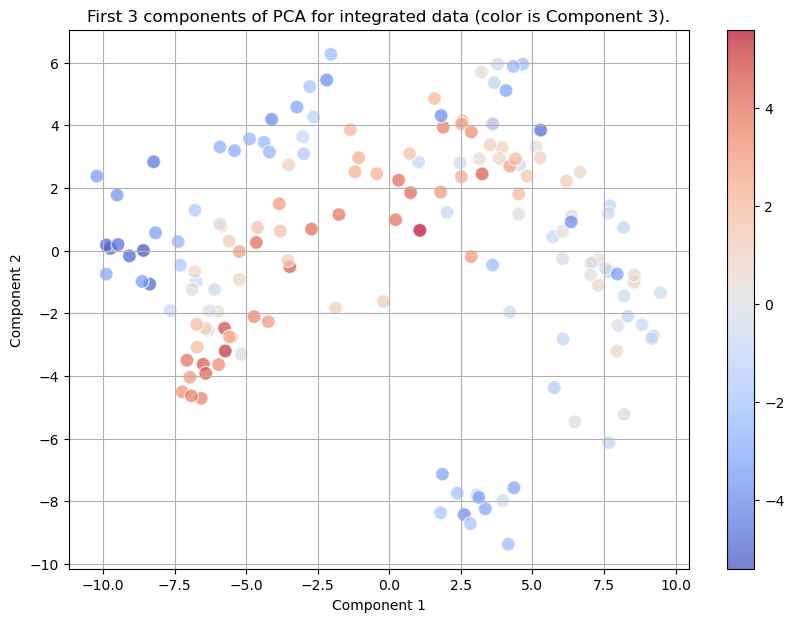

In [15]:
# Principal components to visualize
C1 = df_pca['PCA1']
C2 = df_pca['PCA2']
C3 = df_pca['PCA3']

p.scatter_plot_3d(
    C1,
    C2,
    C3,
    xlabel= 'Component 1',
    ylabel= 'Component 2',
    title= 'First 3 components of PCA for integrated data (color is Component 3).',
    cmap= 'coolwarm'
)


And the following cell shows a way to evaluate the explained variance of each principal component.  

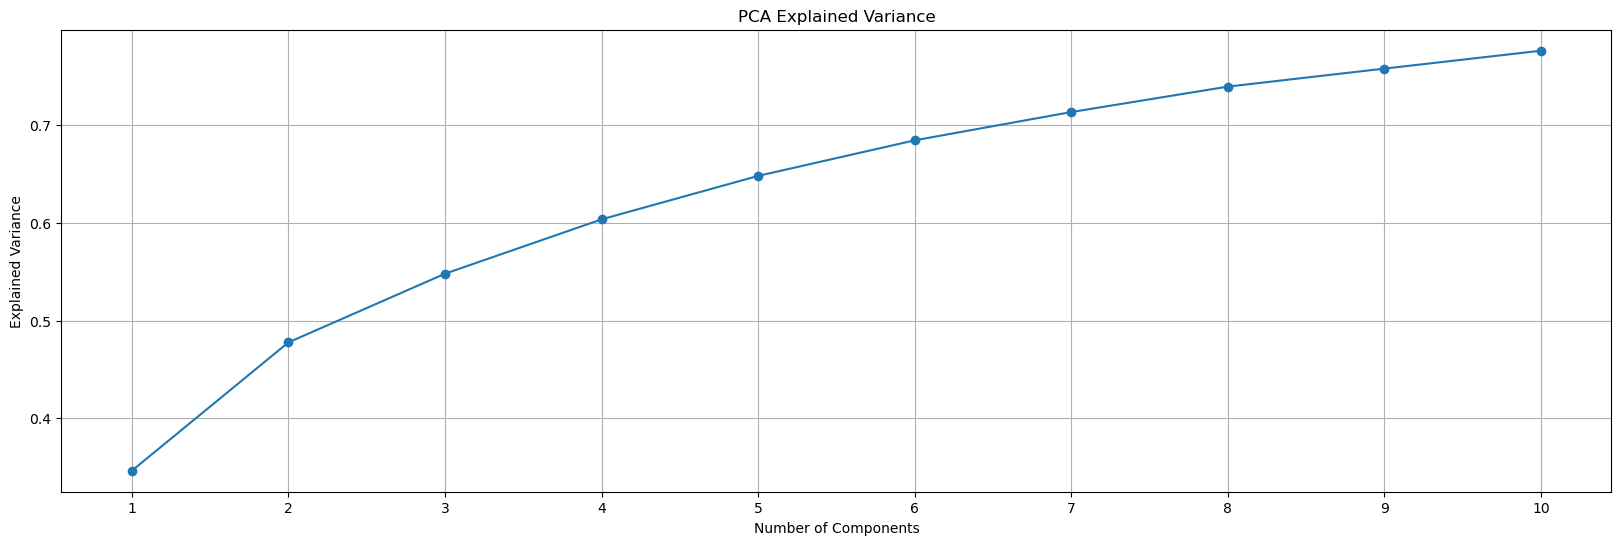

In [16]:
# Save the principal components in order for better visualization
pca_dict = dict()
for i in range(pca.n_components):
    pca_dict[i + 1] = pca_transformed[:, : i + 1]

# Calculate cummulative explained variance
pca_explained_variance = np.cumsum(pca.explained_variance_ratio_)

# Plot 
plt.figure(figsize=(20, 6))
plt.plot(pca_dict.keys(), pca_explained_variance, marker="o")
plt.title("PCA Explained Variance")
plt.xticks(list(pca_dict.keys()))
plt.xlabel("Number of Components")
plt.ylabel("Explained Variance")
plt.grid()
plt.show()

We se, for example, how the first three principal components explains approximatedly $55$ percent of the variance in the data. 

### Multi Omic Factor Analysis (MOFA)
MOFA is more of a framework for integrating data than a method for dimension reduction. Here, MOFA tryes to find an "interpretable low-dimensional representation in terms of a few latent factors" [https://biofam.github.io/MOFA2/ ]. This is done by finding a matrix $Z$ (called the _factor matrix_), and for each set of data $Y_m$ (the DataFrames, called _views_ in this framework) a weight matrix $W_m$ such that $Y_m=ZW_m +\epsilon_m$ with $\epsilon_m$ a despreciable noise.    

The metric used to find the factor (and weights) is similar to the PCA case: one wants to find the representation that best explains the variance in the data, so it minimizes a mean square error (adjusted for multiple views, instead for one combined DataFrame as in PCA).

We will show how the MOFA pipeline works in more detail, but the `MOFA_analysis` and the `MOFA_exp_var` functions from this toolbox can be used to bypass the majority of the steps we will show and obtain the desired outputs.

First, start by creating a "model" object using the path to the files for each normalied data file (not the combined data).

In [17]:
NAMES_DATA = {
    'TEST/processed_data/clr_gene_M1.csv' : 'genes_M1', 
    'TEST/processed_data/clr_taxa_order.csv' : 'taxa_order' , 
}
mdata = create_mudata(NAMES_DATA)
# Check for a correct initialization of the model object 
# Expected warning
mdata

C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\mudata\_core\mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\mudata\_core\mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


MuData object with n_obs × n_vars = 159 × 145
  2 modalities
    genes_M1:	159 x 88
    taxa_order:	159 x 57

The last line must yield the following printed output:

As part of the solver used for MOFA, a `.hdf5` must be created. For this exercise, we use the same folder used to store the MOFA outputs (inside the `processed_data` folder).

In [18]:
MOFA_DIR = "TEST/processed_data/MOFA/"
MODEL_NAME = "mofa_model.hdf5"

##########################################################
#    For each data set (2 in this tutorial), we need to
#    make explicit the type of "noise" we expect for the 
#    latent model.
##########################################################
N_DATA = 2  
lh_list = ["gaussian"]*N_DATA

# Choose the number of factors
N_FACTORS = 10
##########################################################
#    The following `if` statement is used to not overwrite
#    already created files used for the solver.
##########################################################
if not os.path.exists(MOFA_DIR+MODEL_NAME):
    mu.tl.mofa(
        mdata,
        use_obs="union",
        n_factors=N_FACTORS, 
        likelihoods=lh_list,
        convergence_mode="slow",
        outfile=MOFA_DIR+MODEL_NAME,
    )

# We then load the model for analysis
MODEL_PATH = MOFA_DIR+MODEL_NAME
model = mofa.mofa_model(MODEL_PATH)

We now extract the output given by the solver. This is done by creating a DataFrame for the factor (the matrix $Z$) and save it in a folder.

In [19]:
Z = model.get_factors() # Numpy array
df_mofa = pd.DataFrame(Z)
df_mofa.columns = [f"Factor_{i + 1}" for i in range(df_mofa.shape[1])]
df_mofa.index = mdata.obs_names

# Save found factors
du.save_data(df_mofa, MOFA_DIR+'mofa_factors')

# Visualization of the table with the factors
df_mofa.head(8)

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5,Factor_6,Factor_7,Factor_8,Factor_9,Factor_10
S10_Z00,-0.123716,-3.071040,-0.074660,0.697997,-1.879755,0.0,0.0,0.0,0.0,0.0
S10_Z01,-1.278042,-1.658228,-0.226168,0.558041,-0.692027,0.0,0.0,0.0,0.0,0.0
S10_Z05,-1.580628,0.587227,-0.334607,1.119180,0.183604,0.0,0.0,0.0,0.0,0.0
S11_Z00,0.649680,-0.464566,-0.323245,1.492408,0.749950,0.0,0.0,0.0,0.0,0.0
S11_Z01,-0.468545,-1.182001,-0.492880,-0.016823,-0.067455,0.0,0.0,0.0,0.0,0.0
S11_Z03,-1.177648,0.152708,-0.343327,0.493744,0.158945,0.0,0.0,0.0,0.0,0.0
S11_Z05,-0.984208,1.223698,-0.196577,1.115804,0.372505,0.0,0.0,0.0,0.0,0.0
S12_Z00,-0.283390,-3.902236,1.209259,1.519922,-2.299814,0.0,0.0,0.0,0.0,0.0


_NOTE_: For this example, the factors 6 to 10 are pruned by the solver, meaning that the variance of the data explained by more than 5 factors is negligible. As a good practice, one can drop these factors from the data.


In [20]:
factors_to_drop = ['Factor_6','Factor_7','Factor_8','Factor_9','Factor_10']
df_mofa_pruned = df_mofa.drop(columns = factors_to_drop)

# Save and visualize DataFrame without null factor 
du.save_data(df_mofa_pruned, MOFA_DIR+'mofa_factors')
df_mofa_pruned.head(8)

,Factor_1,Factor_2,Factor_3,Factor_4,Factor_5
S10_Z00,-0.123716,-3.071040,-0.074660,0.697997,-1.879755
S10_Z01,-1.278042,-1.658228,-0.226168,0.558041,-0.692027
S10_Z05,-1.580628,0.587227,-0.334607,1.119180,0.183604
S11_Z00,0.649680,-0.464566,-0.323245,1.492408,0.749950
S11_Z01,-0.468545,-1.182001,-0.492880,-0.016823,-0.067455
S11_Z03,-1.177648,0.152708,-0.343327,0.493744,0.158945
S11_Z05,-0.984208,1.223698,-0.196577,1.115804,0.372505
S12_Z00,-0.283390,-3.902236,1.209259,1.519922,-2.299814



_NOTE 3_: The following cell contains a function for which one can obtain the weight matrices ($W_m$) for each _view_ used in MOFA.

In [21]:
def get_weights_MOFA(
    MuData: mu.MuData,
    model: mofa.mofa_model,
) -> dict[str : np.ndarray]:
    """
    Function that retrieves the weight matrices associated with each of the views.

    Parameters
    ----------
        MuData: mu.MuData
            A MuData object containing the model and the data used for MOFA. This object 
            is the output of the `create_mudata` function from the `mofa_utils` module.
        
        model: mofa.mofa_model
            The output of the `mofa_model` function from the `mofa` module, obtained by 
            reading the file created from the original (normalized) data.
    
    Returns
    -------
        output: dict
            A dictionary where the weight matrices are the values, and the keys are 
            strings used to identify them.
    """
    
    W = model.get_weights() #Aggregated weights

    #Split W in sub-matrices corresponding to the weightsfor each view
    n_data = {
        name: mod.n_vars for name, mod in MuData.mod.items()
             }
    slice_limits = np.cumulative_sum([*n_data.values()], include_initial=True)
    idx_data = {
        [*n_data.keys()][k]: slice(
            slice_limits[k],
            slice_limits[k+1],
        ) for k in range(MuData.n_mod)
    }
    output = {
        name: W[index,:] for name, index in idx_data.items()
    }
    return output

As we mention before, instead of constructing $Z$ and the weight matrices, we can use the `MOFA_analysis` function from the `mofa_utils` library from this toolbox. As outputs, it calculates the factor matrix and each weight matrix and save them in the specified directory. As an option, the function can also returns the weight matrices as DataFrames. It is worth mentioning that this function will include and save all factors, including those that are null. 

After we apply MOFA, as with PCA, one can plot any 3 factors for visualization.

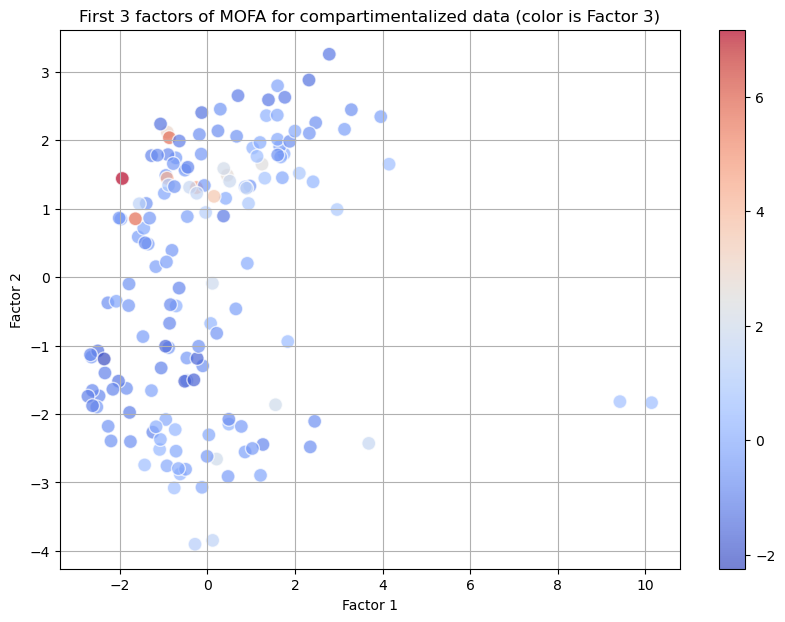

In [22]:
F1 = df_mofa['Factor_1'] 
F2 = df_mofa['Factor_2'] 
F3 = df_mofa['Factor_3'] 

p.scatter_plot_3d(
    F1,
    F2,
    F3,
    xlabel='Factor 1',
    ylabel='Factor 2',
    title = 'First 3 factors of MOFA for compartimentalized data (color is Factor 3)',
    cmap = 'coolwarm'
)

We can evaluate how good is the MOFA output by creating a table or a plot for the explianed variance by each factor, individualy for each view.

In [23]:
# Extracting the explained variance for each factor
variance_explained = model.get_r2()
variance_explained.drop(columns=["Group"], inplace=True)
variance_explained["Factor"] = variance_explained["Factor"].str.replace(
    r"Factor(\d{1})$", r"Factor0\1", regex=True
)
variance_explained_pivot = variance_explained.pivot(
    index="Factor", columns="View", values="R2"
)
###################################################################
#    If model that gave null factors as outputs is still open, the
#    table wil show rows with them. One can avoid showing them by
#    only consider (and saving) the top factors which are not null.
###################################################################
variance_explained_table = variance_explained_pivot.head(5) 

# One can save this information for later
variance_explained_table.to_csv(f'{MOFA_DIR}M_variance_explained.csv')

# Use the table and dsplay it as a DataFrame...
variance_explained_table

View,genes_M1,taxa_order
Factor,,
Factor01,44.804702,2.478672
Factor02,11.238531,32.095668
Factor03,14.397334,4.023981
Factor04,5.659857,10.117154
Factor05,3.586860,5.248550


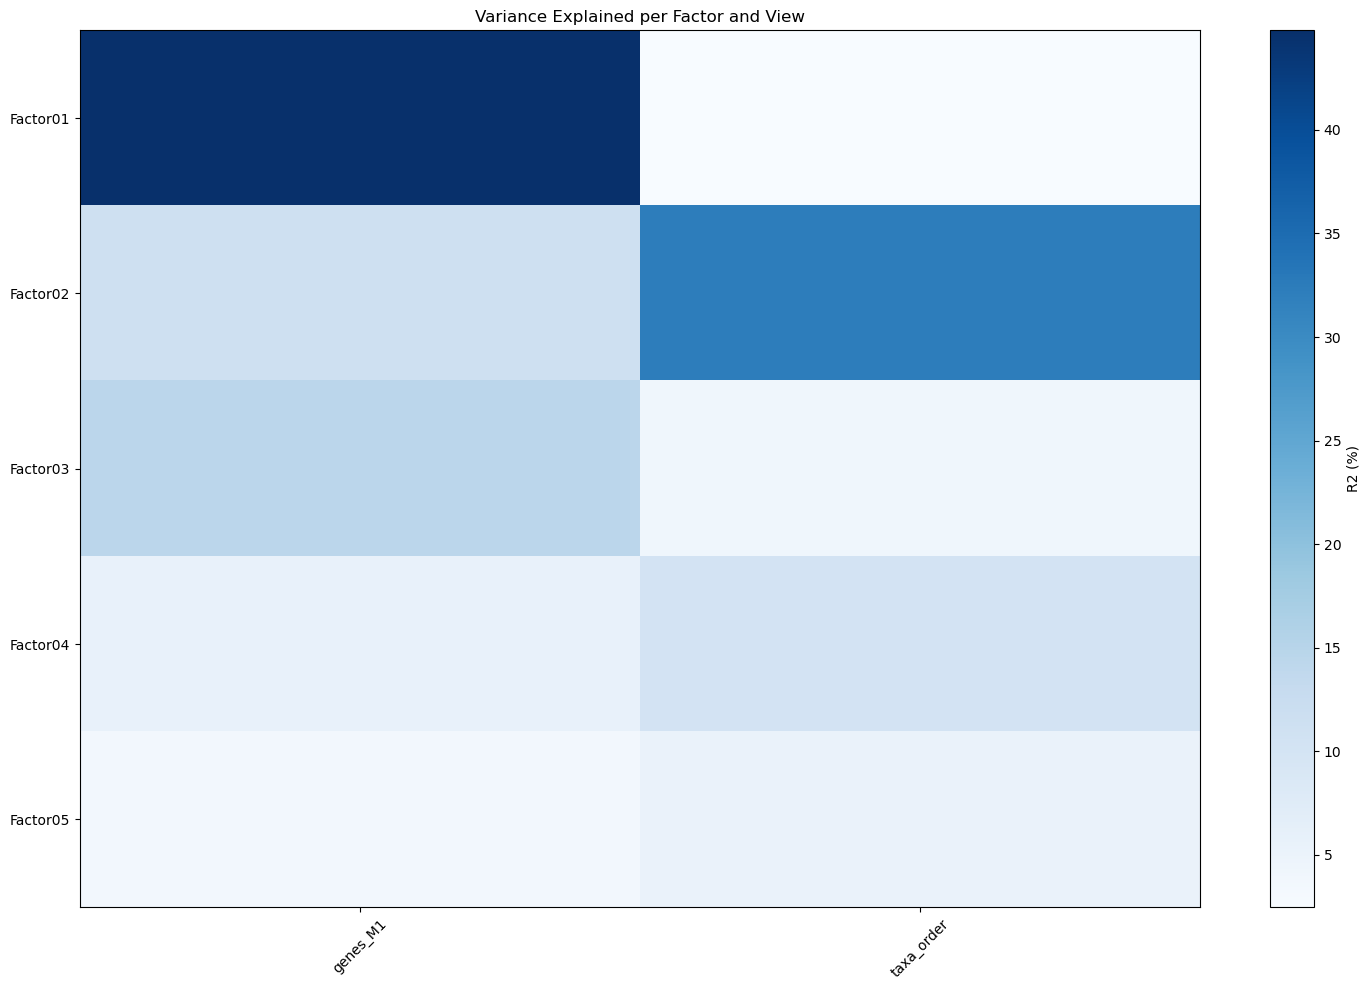

In [24]:
# ... or use it to display as a plot.
plt.figure(figsize=(15, 10))
plt.imshow(variance_explained_table, aspect="auto", cmap="Blues")
plt.xticks(
    ticks=range(len(variance_explained_table.columns)),
    labels=variance_explained_table.columns,
    rotation=45,
)
plt.yticks(
    ticks=range(len(variance_explained_table.index)),
    labels=variance_explained_table.index,
)
plt.colorbar(label="R2 (%)")
plt.title("Variance Explained per Factor and View")
plt.tight_layout()

Both the table and plot could be made with the `MOFA_var_exp` function from the `mofa_utils` library of this toolbox. This fucntion saves the table as a `CSV` file, and the plot can be shown on console. This also will save al factors that are null.   

_NOTE_: After we open the file with the command `model = mofa.mofa_model(MODEL_PATH)` (on second line of the previous cell), the `.hdf5` file cannot be edited util one closes it with the command `model.close()`. 

In [25]:
# After using the model (loaded from the .hdf5 file), we can close it
model.close()

### Uniform Manifold Approximation and Projection (UMAP)
This method comes from topological data analysis, and assumes that the data lives in a latent space (more specific, a manifold) of higher dimension, and tries to adjust its parameters to first find an approximation to that space and then project it into a lower dimension space.

The UMAP method is very non-linear, and is used as a "better" method that t-SNE for large and high-dimension datasets. First, it creates a graph that correlates the data (creates a link betwee samples with "high correlations"), and sets a distance to find the best projection of the graph on a Riemann surface. This is useful to find global structures in the data.



C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.


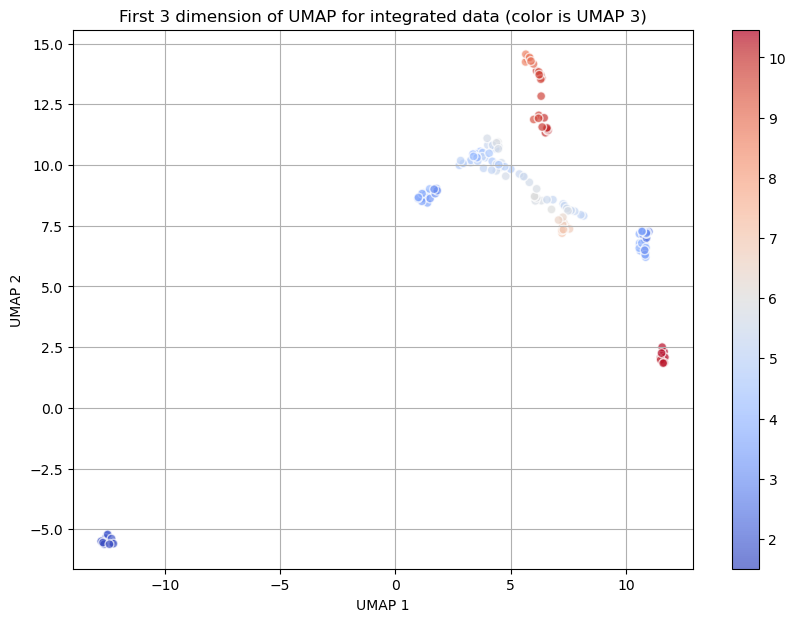

In [26]:
# Hiperparámetros de UMAP. Se pueden modificar para buscar hiperparámetros optimos
########################################################################
#    For this test, the hyperparameters used were chosen after trial and 
#    error. We suggest these because the figure and structure of the
#    projected data achieves a balance between clusterization and visual
#    realtionship.
########################################################################

n_neighbors = 5
min_dist = 0.1
random_state = 0
n_components = 3

# Run UMAP on integrated omic data. 
df_umap = uu.run_umap(
    combined_clr,
    n_neighbors=n_neighbors,
    min_dist=min_dist,
    random_state=random_state,
    n_components=n_components,
)
###############################################################
#    We expect a warning of "n_jobs" because one can implement
#    the solver used in UMAP in a HPC setting, but we developed
#    this tutorial to run in a personal device.
###############################################################

# Save results
UMAP_DIR = 'TEST/processed_data/UMAP/'
du.save_data(df_umap, UMAP_DIR + "combined_umap")


# Similar to other methods, one can plot up to three dimensions
U1 = df_umap["UMAP_1"] 
U2 = df_umap["UMAP_2"] 
U3 = df_umap["UMAP_3"] 
p.scatter_plot_3d(
    U1,
    U2,
    U3,
    xlabel="UMAP 1",
    ylabel="UMAP 2",
    title="First 3 dimension of UMAP for integrated data (color is UMAP 3)",
    s=40,
    alpha=0.7,
    cmap = 'coolwarm',
)

_NOTE_: In the plot above, we can see that some data points (samples) are separated from the rest (bottom left corner). While the relative distance between points does not have a concrete meaning, the relative position —or the "shape" that the projection takes— is meaningful. The "clearly distinct" set of samples will be examined later .

In [27]:
# The bottom-left corner samples have negative values for first dimension.
umap_special = df_umap[df_umap['UMAP_1']<0].index.values #This is a numpy array of strings
print(f'Names of samples with 1st componen less than zero:\n{umap_special}')

Names of samples with 1st componen less than zero:
['S31_Z07' 'S32_Z03' 'S32_Z05' 'S32_Z07' 'S33_Z03' 'S33_Z05' 'S33_Z07'
 'S34_Z03' 'S34_Z05' 'S34_Z07' 'S34_Z09']


## Diferences between methods for reduction of dimensionality
* The main hyperparameter on the PCA implementation is the number of principal components desired for the dimension reduction.
* The number of rows of $Z$ will be the same as the number of samples of $Y_m$, and the number of columns (the individual "factors") is an hyperparameter, similar to the number $p$ of principal components in PCA, choosen by the user.
* For UMAP, the two main hyperparameters are the _minimal distnace_ to consider a sample being connected to another and the _number of neighbors_ needed to consider a relevant group of samples, and their values must be tweaked in order to make a good projection (based on visual verification in a first approach).
* MOFA is implemented to prune (not use) factors that little explains the variance in the data, so the output can have some null factors (columns that are all zero). This is intended, and pruned factors that are mantained do not affect the analysis.
* Both PCA and MOFA can be understood in terms of explained variance. The dimensions for each method (_components_ for PCA, _factors_ for MOFA) can be decomposed as a linear combination of original features of the data, and they are ordered in "variance explicability". UMAP does not have the same capacity, so the dimensions can not be thought as a combination of the features, and as a consecuence the dimensions may not represent any meaningful characteristic of the data.
* As a consecuence of the previous point, there is not an implemented method to assess the quality of the UMAP output in terms of explained variance. Despite this, UMAP can achieve a good representation of the data in terms of global structure, making clusterization easier in the future. To a correct interpretation of UMAP output, see [https://pair-code.github.io/understanding-umap/ ] and in particular the section "How to (mis)read UMAP".
* UMAP is a stochastic method for dimension reduction, so it might be reasonable to consider many diferent instnaces for data analysis. For simplicity, in this tutorial, we are going to use only one instance.

_NOTE_: In a simple fashion, it is possible to create a side-by-side comparison of two scatter plots. This is useful for observing the differences between various dimensionality reduction methods.

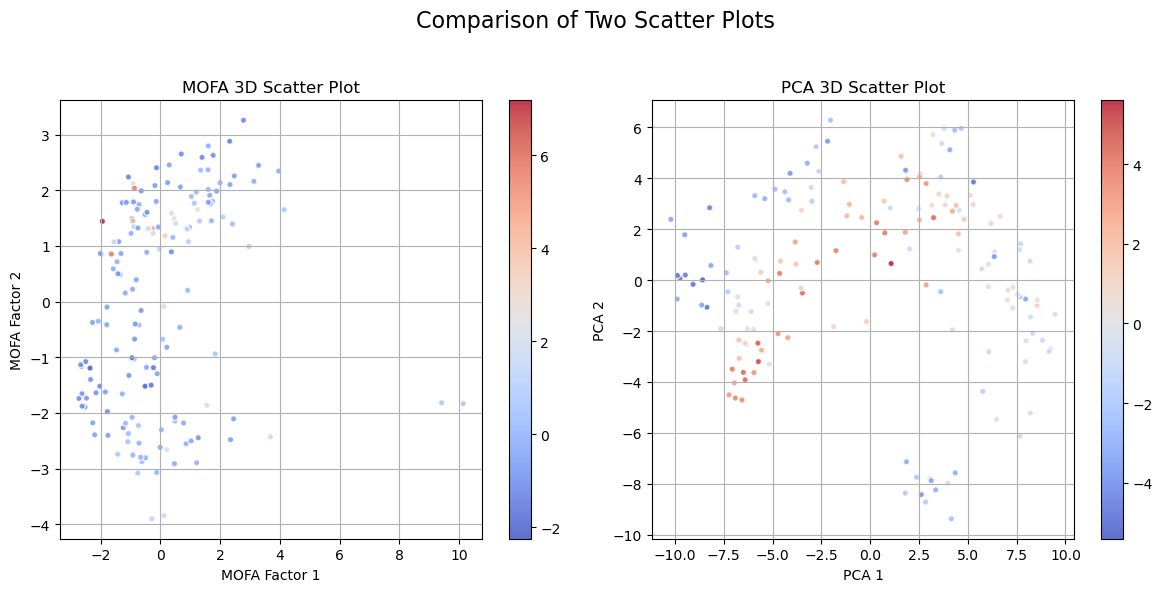

In [28]:
# Set dimensions to show
pca_1 = df_pca["PCA1"]
pca_2 = df_pca["PCA2"]
pca_3 = df_pca["PCA3"]

mofa_1 = df_mofa_pruned["Factor_1"]
mofa_2 = df_mofa_pruned["Factor_2"]
mofa_3 = df_mofa_pruned["Factor_3"]

# Plot with a double-scatter plot
p.doble_scatter_plot_3d(
    mofa_1,
    mofa_2,
    mofa_3,
    pca_1,
    pca_2,
    pca_3,
    xlabel1="MOFA Factor 1",
    ylabel1="MOFA Factor 2",
    xlabel2="PCA 1",
    ylabel2="PCA 2",
    title1="MOFA 3D Scatter Plot",
    title2="PCA 3D Scatter Plot",
    s=20,
    cmap='coolwarm', alpha=0.8
)

## How to visualize and study the metadata after dimension reduction
In order to explore how the metadata relates to the data, an example of how to visualize metadata for dimensionality-reduced data is presented below.

In this instance, various pieces of metadata are displayed in relation to the first two dimensions of the data transformed via UMAP (one can choose any other projection). It should be noted that most of the columns in the current metadata set contain numerical entries; therefore, it is simpler to skip any columns that correspond to non-numerical data.

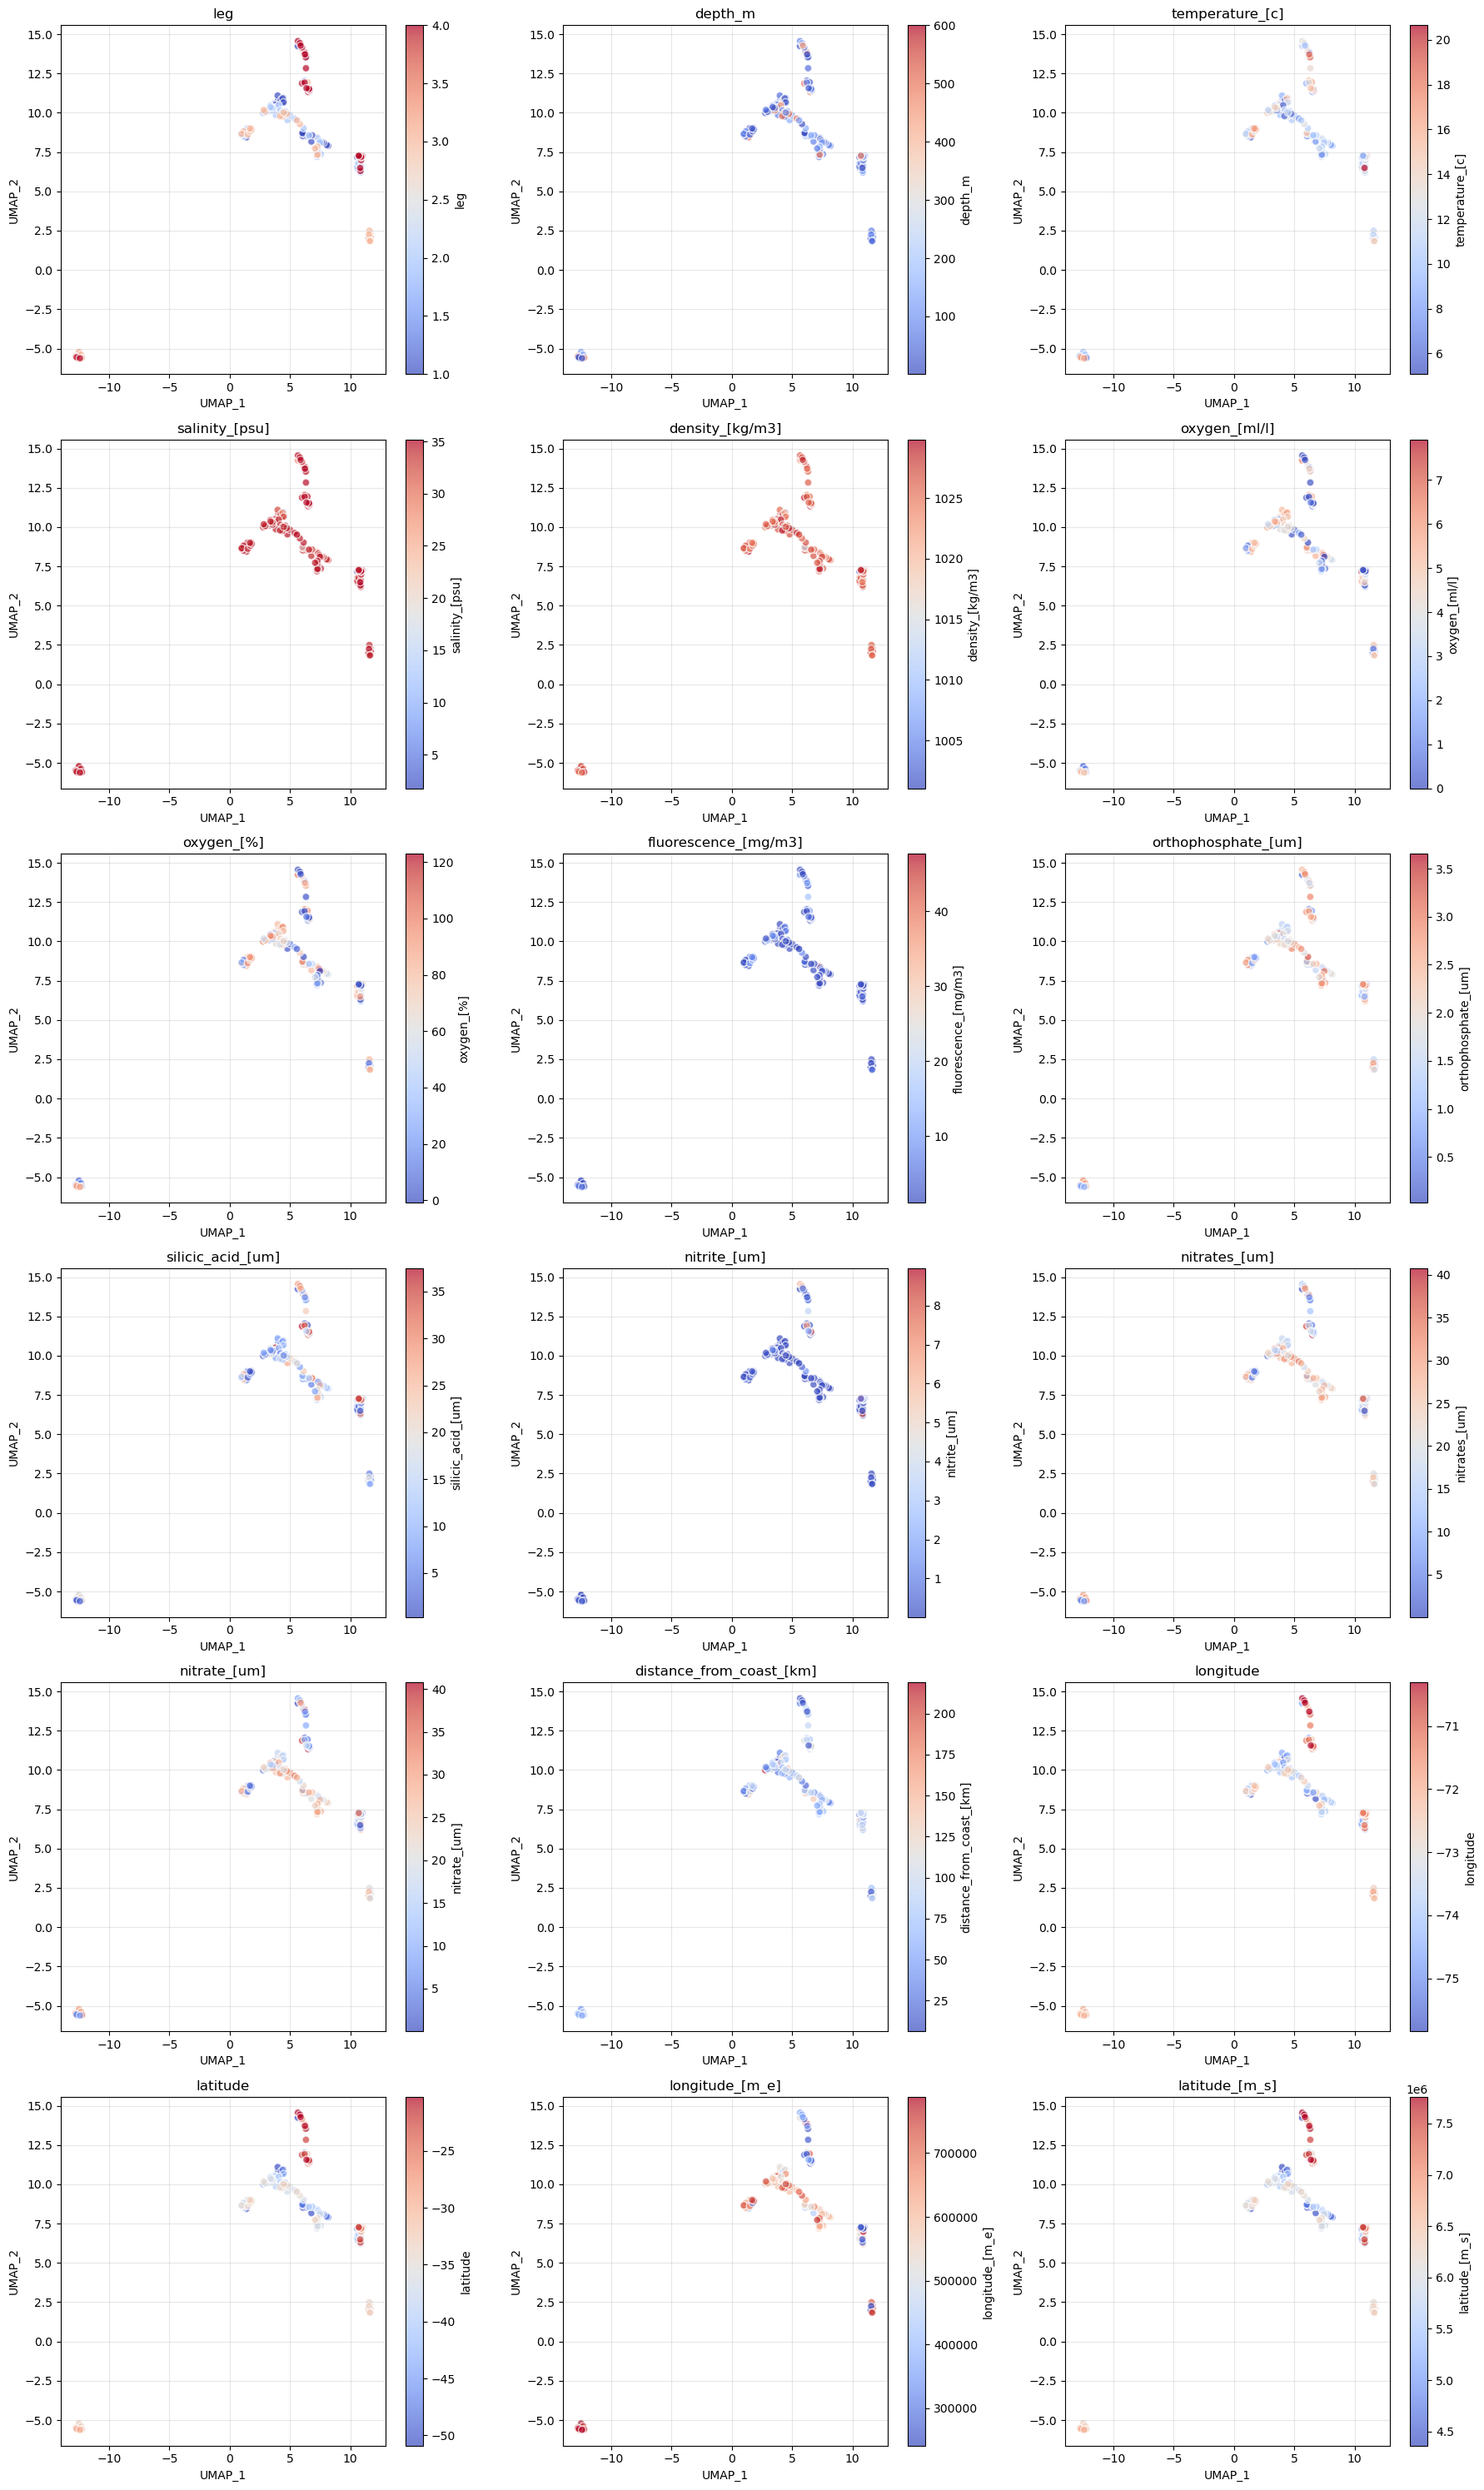

In [29]:
numerical_columns_metadata = Metadata_aggregated_pd.select_dtypes(
    include=[np.number]
).columns.tolist()
to_remove = ["day", "hour", "minute", "second", "year", "month"]
for col in to_remove:
    numerical_columns_metadata.remove(col)
del to_remove

columns_metadata = numerical_columns_metadata
X_axis, Y_axis = "UMAP_1", "UMAP_2"
p.plot_dim_reduction_metadata(
    df_umap[X_axis], 
    df_umap[Y_axis], 
    Metadata_aggregated_pd, 
    columns_metadata, 
    dim_labels = (X_axis, Y_axis), 
    cmap='coolwarm'
)

# Analysis
The main clustering processes, IT Pareto analysis, and predictive models implemented are presented below.

## Clustering algoithms: how they work and how to choose
There are three types of clustering methods available: K-means, Gaussian Mixture Model (GMM), and Density-based spatial clustering of applications with noise (DBSCAN).

For the following examples, we will use data projected via MOFA for the first two algorithms, and UMAP is used for the third one.

### K-means
K-means takes the number of clusters to be identified as a hyperparameter. Therefore, an optimizer is implemented to determine the optimal number of clusters that yields the best Silhouette score, based on the "elbow method."

*When importing the libraries, a line of code is included that sets the number of threads to 1. This prevents a "memory leak" warning when implementing K-means. If multithreading is desired, a solution compatible with the current implementation must be found. Other warnings can be ignored.*

In [30]:
###################################################################
#    The output of the optimization for K-means is a dictionary
#    with all the results of a K-means algorithm with a diferent
#    number of clusters. The range in this case goes from 2 to 12,
#    and the dictionary has all the information for deciding which
#    'k' number for clusters is better. This is done automatically
#    using the "elbow method" for maximal silhouette.
###################################################################

mofa_kmeans_res = cu.run_kmeans_optimization(df_mofa_pruned, k_range=range(2, 12)) #posible warning

# Best 'k' (number of clusters) found
opt_k_mofa = mofa_kmeans_res["optimal_k"]
print(f"MOFA Optimal k detected: {opt_k_mofa}")

MOFA Optimal k detected: 7


C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md



One can simply trust the method and use the clustering with the "best" $k$ for the number of clusters. Other clusterization attempts (used with different $k$'s) can still be accessed on the `mofa_kmeans_res` dictionary.

If one wishes to, the following cell shows how to visualize the "elbow of cohesion" plot and a "silhouette" plot, where the marked line points to the best number of cluters found and their scores in each plot.

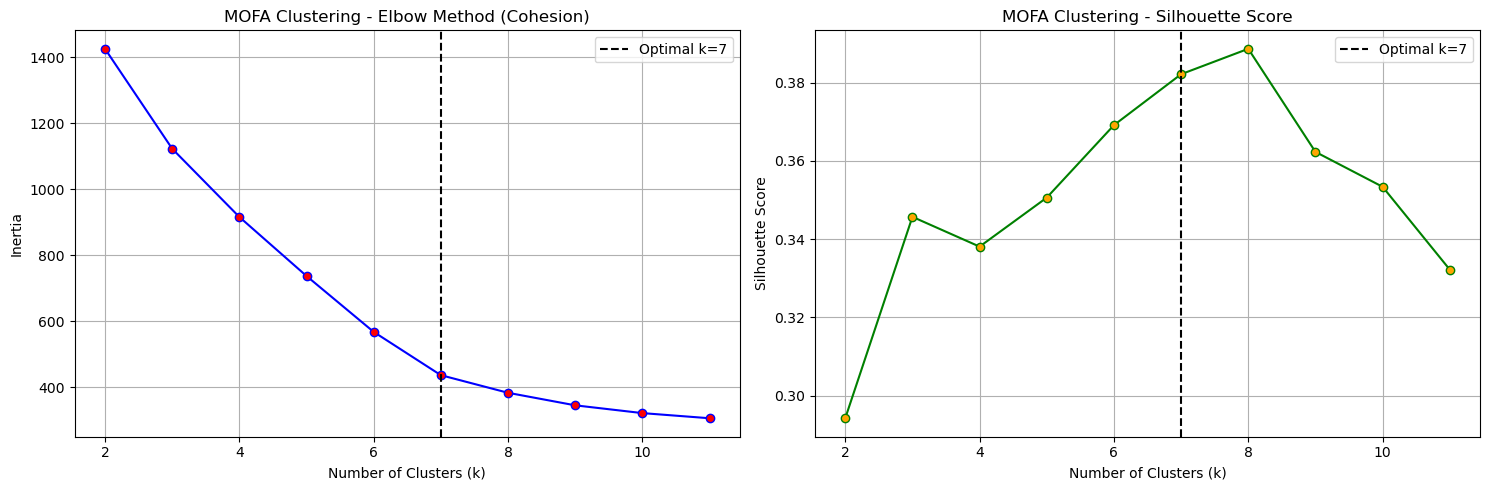

In [31]:
p.plot_elbow_silhouette(
    mofa_kmeans_res["k_range"],
    mofa_kmeans_res["inertias"],
    mofa_kmeans_res["silhouettes"],
    opt_k_mofa,
    "MOFA Clustering",
)

One can also plot the proximity matrix for the K-means clusterization (in this case, using the best clusteriation found).  

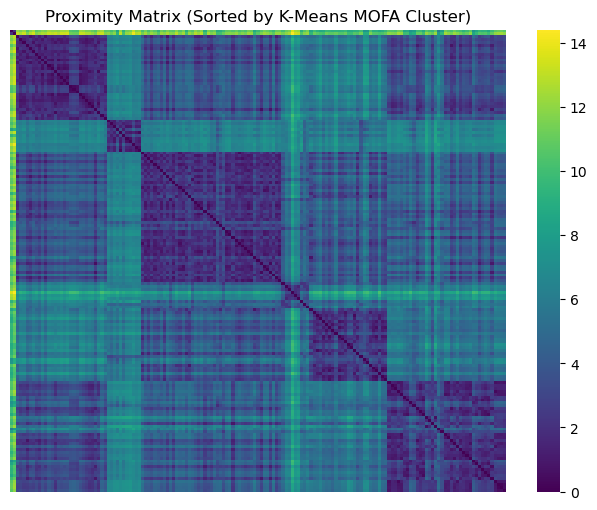

In [32]:
# First, retrieve the labels for the clusters
labels_mofa = mofa_kmeans_res["results"][opt_k_mofa]["labels"]

# Sort samples for clusters for visualization 
m_factors_ordered = df_mofa_pruned.copy()
m_factors_ordered["Cluster"] = labels_mofa
m_factors_ordered = m_factors_ordered.sort_values("Cluster")

# Main function used to extract the proximity matrix
dist_matrix = cu.get_proximity_matrix(m_factors_ordered.drop(columns="Cluster"))

#Plotter
plt.figure(figsize=(8, 6))
sns.heatmap(dist_matrix, cmap="viridis", xticklabels=False, yticklabels=False)
plt.title("Proximity Matrix (Sorted by K-Means MOFA Cluster)")
plt.show()

### GMM
Since GMM takes the number of clusters as a hyperparameter (similar to K-means), an optimizer is run to search the optimal number of clusters based on the Bayesian Information Criterion (BIC) and the Akaike Information Criterion (AIC). 

The output of the `optimize_gmm` method is also a dictionary with other clusterization attempts, so other $k$ number of clusters used for GMM can still be used.  

Best K based on BIC: 6


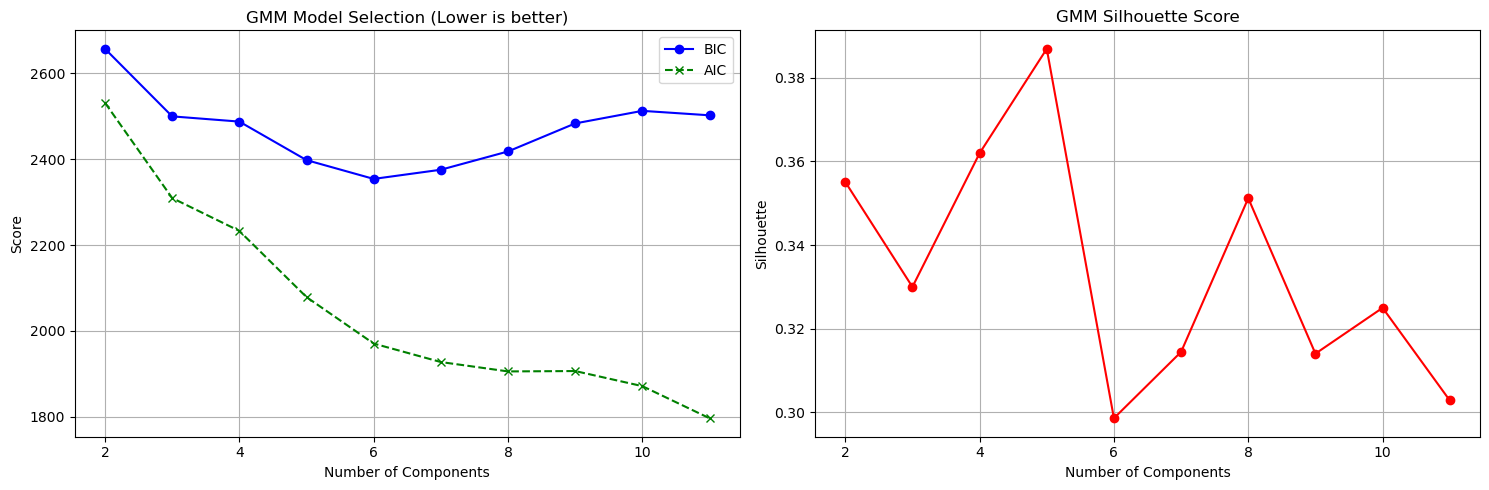

In [33]:
###########################################################
#    The output of the optimization for GMM is also a 
#    dictionarylike in the example for K-means. the range  
#    in this case alsogoes from 2 to 12, and the dictionary 
#    has all the information needed to find the lowest BIC
#    or AIC score with the highest silhouette possible. 
###########################################################
gmm_mofa_res = cu.optimize_gmm(df_mofa_pruned, k_range=range(2, 12))
criterion = 'bics' # or 'aics'
best_k_gmm_mofa = gmm_mofa_res["k_range"][np.argmin(gmm_mofa_res[criterion])]

print(f"Best K based on {criterion.upper()[:-1]}: {best_k_gmm_mofa}")


# Plot for BIC and AIC scores alongside with the silhouette score.
p.plot_gmm_optimization(
    gmm_mofa_res["k_range"], gmm_mofa_res["bics"], gmm_mofa_res["aics"], gmm_mofa_res["silhouettes"]
)


Despite being the candidate with the lowest silhouette, $k=6$ is marginaly worse than other values for $k$ and has the lowest score for BIC. 

Only to compare, we can plot the proximity matrix for $k=5$ and $k=6$.

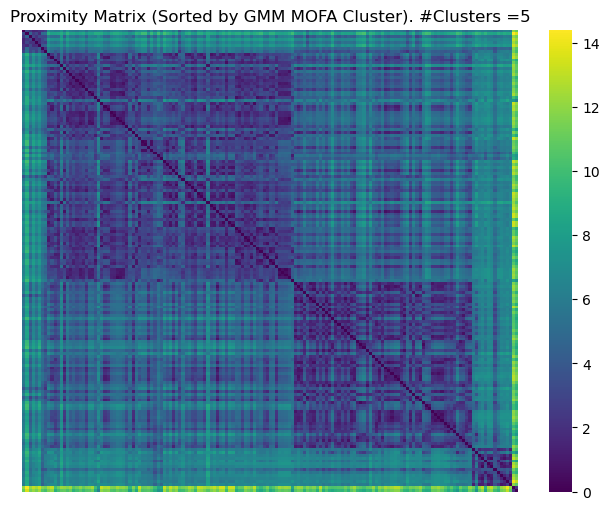

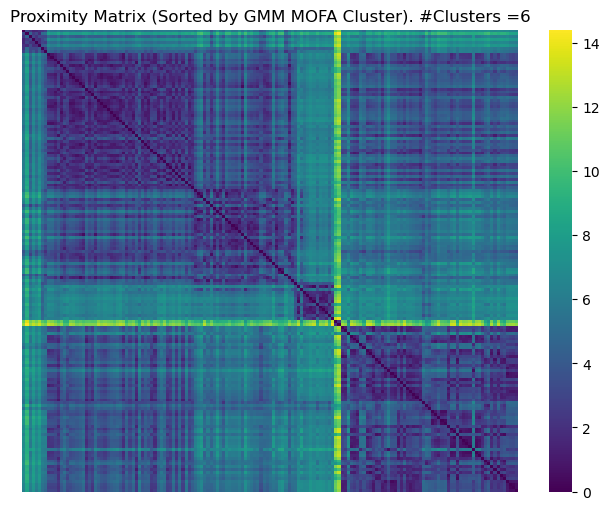

In [34]:
for k in [5,6]:
    #Se decide el número de clusters a utilizar con K-means 
    #Se extraen nombres de clusters
    labels_gmm_mofa_opt = gmm_mofa_res["results"][k]["labels"]
    
    # #Se ordenan datos según clusters
    mofa_ordered_gmm = df_mofa_pruned.copy()
    mofa_ordered_gmm["Cluster"] = labels_gmm_mofa_opt
    mofa_ordered_gmm = mofa_ordered_gmm.sort_values("Cluster")
    
    #Función principal para obtener matriz de proximidad
    dist_matrix_gmm_mofa = cu.get_proximity_matrix(
        mofa_ordered_gmm.drop(columns="Cluster")
    )
    
    #Plotter
    plt.figure(figsize=(8, 6))
    sns.heatmap(dist_matrix_gmm_mofa, cmap="viridis", xticklabels=False, yticklabels=False)
    plt.title(f"Proximity Matrix (Sorted by GMM MOFA Cluster). #Clusters ={k}")
    plt.show()

### DBSCAN
To find suitable hyperparameters for running DBSCAN, one can define an array of potential candidates.

This approach works best on data that has undergone dimensionality reduction using a "topological" method, such as UMAP.

In general, selecting good candidates can be facilitated by examining a plot of the projected data to determine the following:
1. Choose `epsilon` values that vary according to the order of magnitude of the distances between points. Larger values simplify the model (resulting in a very low number of clusters), while smaller values increase complexity (leading to a higher number of clusters).
2. Select `min_samples` based on clear or obvious groupings visible in the plot. Higher values make it more difficult for clusters to form (resulting in a higher number of clusters), while lower values facilitate cluster formation (leading to a lower number of clusters).

In the DBSCAN algorithm, some data points may be classified as "noise." When discussing the number of clusters identified by DBSCAN, these noise points are excluded—effectively treating them as a non-cluster category.

*In the current implementation, 'eps' and 'min_samples' are the hyperparameters. Based on a plot of the data projected via UMAP into its first three dimensions, the search range for 'eps' is set from 0.01 to 0.5 (in increments of 0.01), while the range for 'min_samples' is set from 2 to 10 (in increments of 1). The top 10 parameter combinations are presented, with the selection criteria favoring a high silhouette score alongside a low noise ratio.*

In [35]:
# Candidates for hyperparameters
eps_candidates = np.arange(0.05, 1.5, 0.05) # must be chosen with the projection in mind
min_samples_candidates = [2,3,4,5,6,7,8,9,10]

# Optimizer for hypermarameters, returns a table
dbscan_table = cu.grid_search_dbscan(df_umap, eps_candidates, min_samples_candidates)

# display table for used data
dbscan_table_filtered = dbscan_table[
    (dbscan_table["n_clusters"] > 1) & (dbscan_table["noise_ratio"] < 1) & (dbscan_table["silhouette"]>0)
].sort_values("silhouette", ascending=False)
display(dbscan_table_filtered.head(10))

,eps,min_samples,n_clusters,n_noise,noise_ratio,silhouette,labels
179,1.00,10,7,9,0.057,0.715,"[6, 6, 0, 6, 6, 0, 0, 1, 0, 0, 1, 1, 2, 0, 3, ..."
170,0.95,10,7,9,0.057,0.715,"[6, 6, 0, 6, 6, 0, 0, 1, 0, 0, 1, 1, 2, 0, 3, ..."
150,0.85,8,8,0,0.000,0.714,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."
140,0.80,7,8,0,0.000,0.712,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."
102,0.60,5,10,3,0.019,0.675,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."
101,0.60,4,10,3,0.019,0.675,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."
90,0.55,2,10,2,0.013,0.674,"[0, 0, 1, 2, 0, 1, 1, 3, 1, 1, 3, 3, 4, 1, 5, ..."
91,0.55,3,10,2,0.013,0.674,"[0, 0, 1, 2, 0, 1, 1, 3, 1, 1, 3, 3, 4, 1, 5, ..."
112,0.65,6,10,5,0.031,0.671,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."
113,0.65,7,10,5,0.031,0.671,"[0, 0, 1, 0, 0, 1, 1, 2, 1, 1, 2, 2, 3, 1, 4, ..."


In this step, we focus on the best-ranked 'min_samples' values. The process of setting 'eps' and 'min_samples' is part of the modeling phase; therefore, there are no "a priori" correct answers (though choices should certainly be well-informed). The key is to balance the metrics (silhouette score and noise ratio) against the chosen hyperparameter ranges and the expected number of clusters.

Another approach for selecting 'eps' involves examining a plot of the distance to the $k$-th nearest neighbor (NN-distance) for various potential values of $k$ (where $k = \text{min\_samples}$). For each data point, we calculate the distance to its $k$-th nearest neighbor, then sort all data points in ascending order based on these distances. We then select an 'eps' value near the point where the curve begins to accelerate—that is, the threshold beyond which the NN-distances for the remaining data points start to increase rapidly.

Our goal is to plot these (sorted) distances and identify the inflection point on the graph where the rate of distance increase accelerates; the epsilon value corresponding to this point is then chosen. For instance, looking at the table, we can see that combination 150 (ranked 3rd), with 'min_samples = 8', yields a lower silhouette score than the top two combinations, but it results in zero noise (n_noise = 0). We will now examine the 8-distance plot.

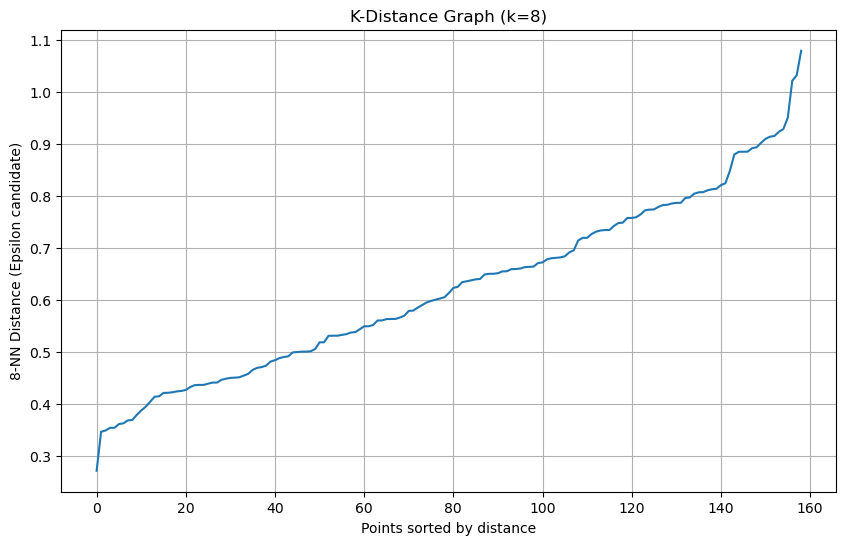

In [36]:
k_neighbors = 8
distances_data = cu.calculate_k_distance(df_umap, k=k_neighbors)
p.plot_k_distance_curve(distances_data, k=k_neighbors)

An acceleration point relates to a change in the trend. In the plot, we can see that the curve grows in a controlled manner up to a certain point: around 0.82, a steeper growth is observed. We therefore choose 'eps' equal to 0.82 for this example.

In the following cell, we run the optimizer for DBSCAN and extract the labels assigned to each sample.

In [37]:
# Run optimizer for DBSCAN 
labels_dbscan_opt = cu.run_dbscan(df_umap, eps=0.82, min_samples=8)["labels"]

#################################################
#    The following 'if'/'else' statements handles
#    the case when the optimizer assigns the
#    label '-1' to the data marked as noise.
#################################################

if -1 in labels_dbscan_opt:
    N_clusters = len(np.unique(labels_dbscan_opt))-1
else:
    N_clusters = len(np.unique(labels_dbscan_opt))

print(f"Number of clusters found: {N_clusters}")

Number of clusters found: 8


As in previous examples, one can obtain the proximity matrix. We skip this process for because it has been already shown two times.

_Note_: one of the reasons that we choose the UMAP projection for this cluterization method is that other projections dosen't clusterize as good as UMAP. This is because DBSCAN has a high possibility of assigning "noise" to the PCA and MOFA projections obtained in this tutorial. This suggest another way for deciding the numbero fo components or factors used in PCA or MOFA respectively: to choose the number of dimensions that maximizes the clusterization quality (silhouette score, for example). For this tutorial, we are not going to show how to do it, but is not something difficult to do if we use what has been already shown. 

We now show briefly how to save the clusterized data as a `CSV` file.

In [38]:
# Use DataFrame to add labels 
df_dbscan_clusters = pd.DataFrame(labels_dbscan_opt, index=df_umap.index, columns=["Cluster"]) 

# Save as CSV file
CLUSTERS_DIR = "TEST/clusters/"
du.save_data(df_dbscan_clusters, CLUSTERS_DIR+"C_umap_dbscan" )

## Visualizing clusterized data and distribution in metadata
In order to study the clusters found, we first show how load the clusters and add them to the samples in a simple fashion. 

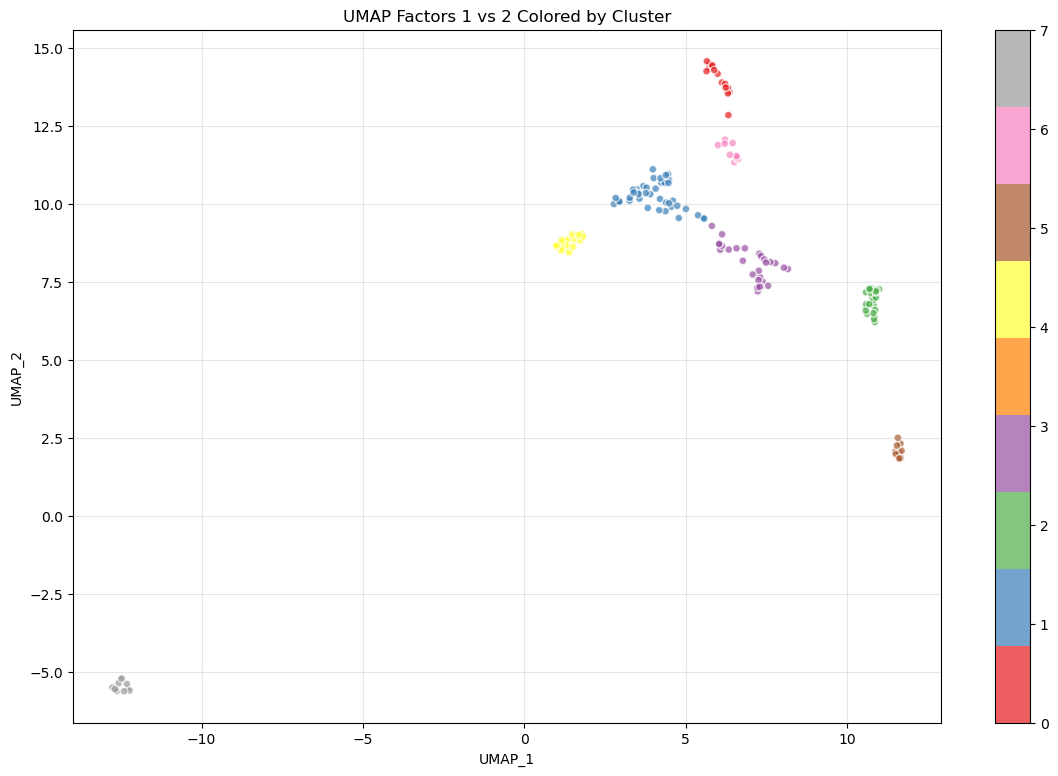

In [39]:
# Load clusters from chosen directory
C_PATH = "TEST/clusters/C_umap_dbscan.csv"
selected_clusters = du.load_data(C_PATH, index_col = 0)

###########################################################################################
#    This step involves using a projection (that is compatible with the selected clusters)
#    and the metadata to visualize each cluster's distribution. For visualization of
#    clusters in a projection, one simply use the DataFrame for the projection; for spatial
#    visualization or distribution of clusters for a set of non-geospatial metadata, we add 
#    the clusters to the aggregated metadata.
###########################################################################################

# Starting with projected data
projection_umap = du.load_data("TEST/processed_data/UMAP/combined_umap.csv", index_col=0) # or use 'df_umap' instance
umap_dbscan_clusters = projection_umap.join(selected_clusters)

# ### alternative: 
# umap_dbscan_clusters = projection_umap.copy()
# umap_dbscan_clusters["Clusters"] = selected_clusters["Cluster"].values

# Plot clusters in projection
X = umap_dbscan_clusters["UMAP_1"]
Y = umap_dbscan_clusters["UMAP_2"]
clusters = umap_dbscan_clusters["Cluster"] 
p.scatter_plot_2d(
    X,
    Y,
    c=clusters,
    xlabel="UMAP_1",
    ylabel="UMAP_2",
    title="UMAP Factors 1 vs 2 Colored by Cluster",
    s=30,
    alpha=0.7,
    cmap = 'Set1',
)

_NOTE_: We add the DataFrame with the projection and the clusters as a safety measure. One can simply use the original data projected DataFrame and the clusterized separatedly, but may happen that both DataFrames are loaded with their index in diferent order. Using `.join()` to concatenate the DataFrames makes sure the clusters are assigned correctly to each sample. 

Now, we visualize the clusters using the metadata. First, we show how to plot the samples colored by cluster in a (simple) spatial plot. After this, we will show how the visualize the distribution of each cluster for other metadata. 

For the spatial visualization, there are two functions: a 2D projection for a determined deep (not a global plot), and a 3D plot for all the data.  

Before we plot, we load the metadata (or reuse the `Metadata_aggregated_pd` DataFrame) and add the clusters to the DataFrame as we did in the projected data DataFrame.

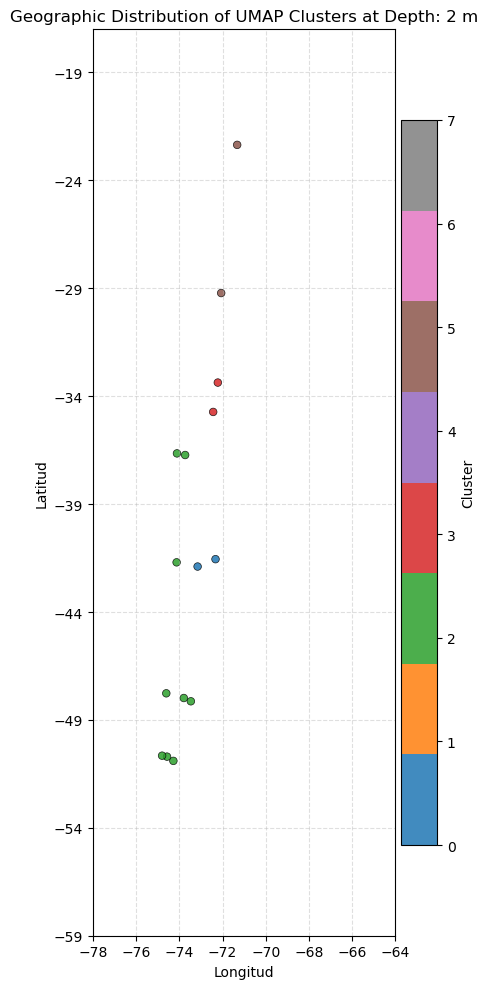

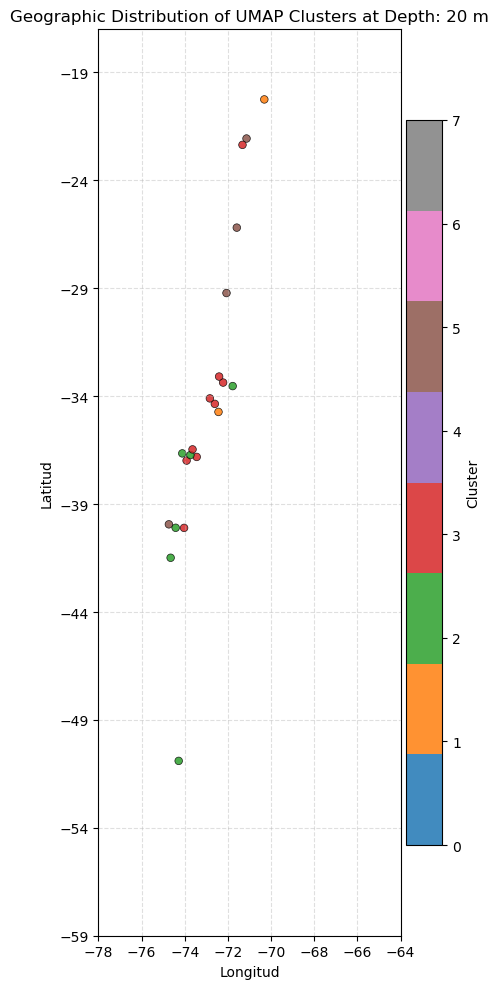

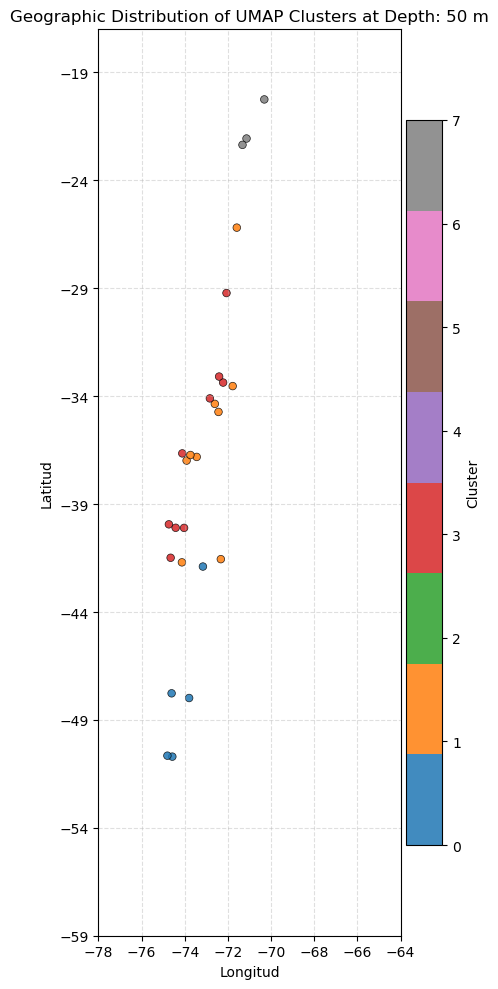

In [40]:
# Load metadata
metadata = du.load_data("TEST/processed_data/Metadata_combined.csv", index_col=0)

# Concatenate DataFrames of metadata and clusters (previously loaded)
metadata_clustered = metadata.join(selected_clusters)

# 2D plot at three diferent depths: 2m, 20m, and 50m.
depths = [2,20,50]
for depth in depths: 
    # Filter for desired depth
    metadata_depth = metadata_clustered[metadata_clustered["depth_m"] == depth]
    # Plot 2D 
    p.plot_geo_clusters(
        metadata_depth,
        metadata_depth["Cluster"],
        lat_col="latitude",
        lon_col="longitude",
        title="Geographic Distribution of UMAP Clusters at Depth: " + str(depth) + " m",
        n_clusters=len(metadata_clustered["Cluster"].unique()),
    )


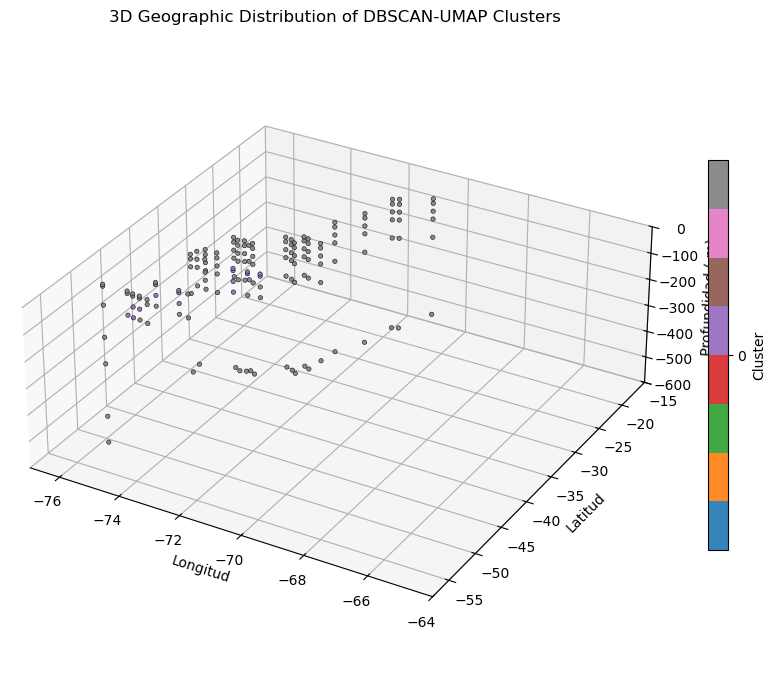

In [41]:
# A 3D global plot
p.plot_geo_clusters_3d(
    metadata_clustered,
    metadata_clustered["Cluster"],
    lat_col="latitude",
    lon_col="longitude",
    depth_col="depth_m",
    title="3D Geographic Distribution of DBSCAN-UMAP Clusters",
    n_clusters=len(metadata_clustered["Cluster"].unique()),
)

It is possible to analyze the data distribution, with box plots, for the physicochemical quantities found in the metadata, broken down by cluster. To do this, the metadata elements to be visualized are selected, and box plots are displayed for each cluster.

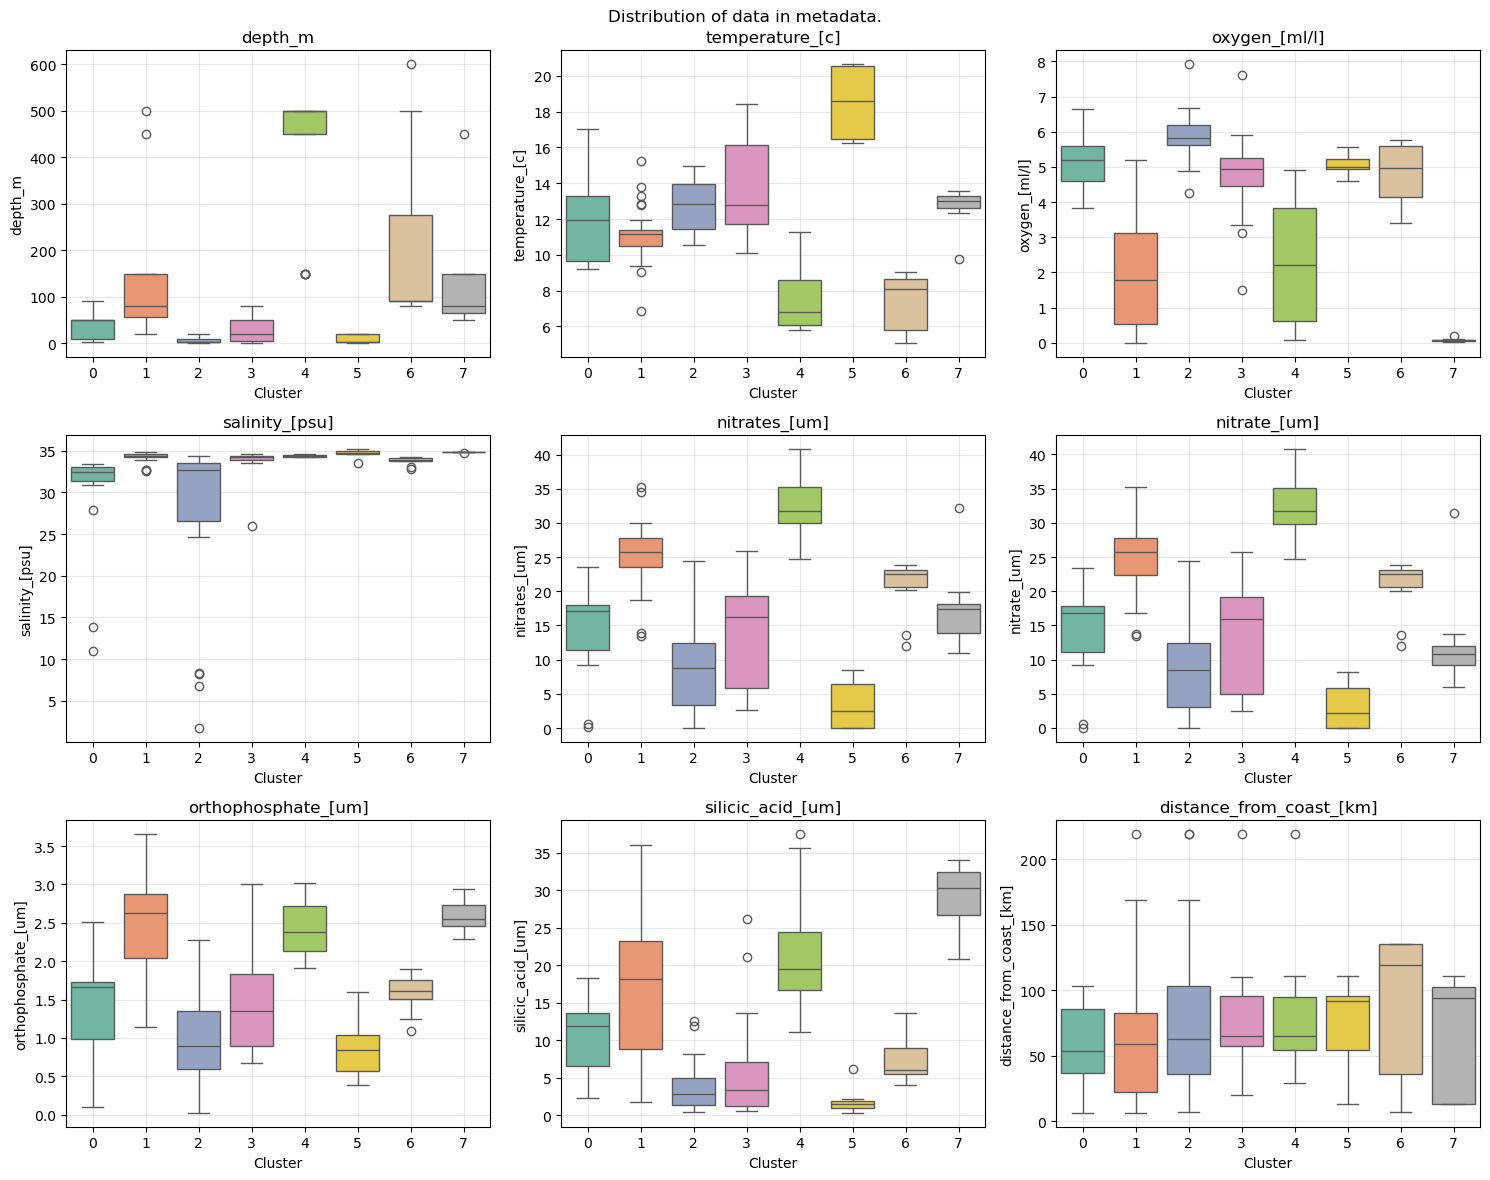

In [42]:
# List the desired environmental variables in metadata
env_vars = [
  "depth_m",
  "temperature_[c]",
  "oxygen_[ml/l]",
  "salinity_[psu]",
  "nitrates_[um]",
  "nitrate_[um]",
  "orthophosphate_[um]",
  "silicic_acid_[um]",
  "distance_from_coast_[km]",
]

# Plot using same DataFrame as with spatial plots
p.plot_metadata_by_cluster(
    metadata_clustered, 
    metadata_clustered["Cluster"], 
    env_vars, 
    title = 'Distribution of data in metadata.'
)

_NOTE_: we see that the cluster $7$ (gray one) corresponds to the minimum oxigen region, and in the UMAP projection is characterized by being clearly appart of the rest of the data. This is expected.

## Pareto TI: How it works and how to implement 
Pareto TI can be applied to identify biological archetypes and their associated tasks within the latent space generated by dimensionality-reduced data (e.g., using MOFA or UMAP).

For this example, the first 3 MOFA factors will be used. This is done to facilitate the generation of plots; therefore, if more dimensions, factors, or components are used, some visualizations may not be available.

Similar to the clusterization methods applied before, we can explore first the optimal number of archetypes to use. 

Input shape: (159, 3)




Table for best candidates


,k,ev,t_ratio
0,2,0.478606,NaN
1,3,0.763865,NaN
2,4,0.958819,0.418241
3,5,0.987299,0.702974
4,6,0.996452,0.847725


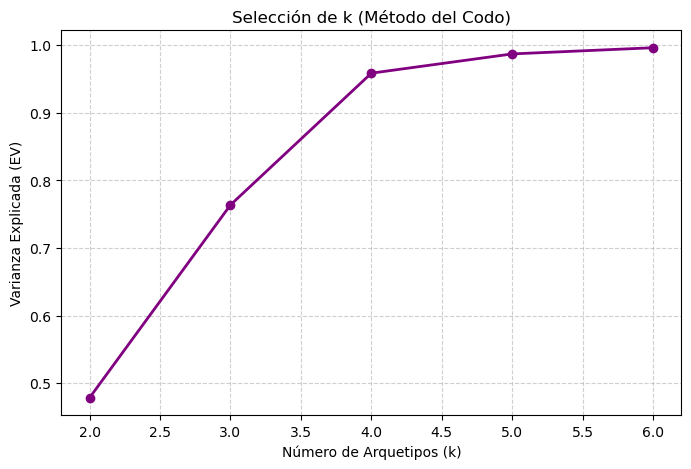

In [43]:
# We set the first three factors of MOFA projection. 
X = np.float32(df_mofa.iloc[:, :3].values)
print(f"Input shape: {X.shape}")
print("\n")
print("="*23)
print("\n")
# Look for candidates for 'k' the umber of archetypes
results_k_list = []
for k in range(2, 7):
    res_k = pu.fit_pcha_partipy(X, k=k, max_iter=500, tol=1e-4, delta=0.0)
    results_k_list.append(
        {"k": k, "ev": res_k["explained_variance"], "t_ratio": res_k["t_ratio"]}
    )

results_k_df = pd.DataFrame(results_k_list)

# Display results as a table and plot for elbow method 
print("Table for best candidates")

display(results_k_df) #table
print("\n")
p.plot_pareto_ev_curve(results_k_list) #plot

With both the table and the plot, we can determine that the best candidate for the number of archetypes is $k=4$. This is because its _t-ratio_ score is the lowest among all valid scores. 

Once the number of archetypes to be considered is chosen, the associated polytope is determined and plotted. In addition, the explained variance is calculated.

C:\Users\Milan Cabezas\Desktop\Mathomics\Omic integration\new_omic_integration\src\plots.py:630: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored


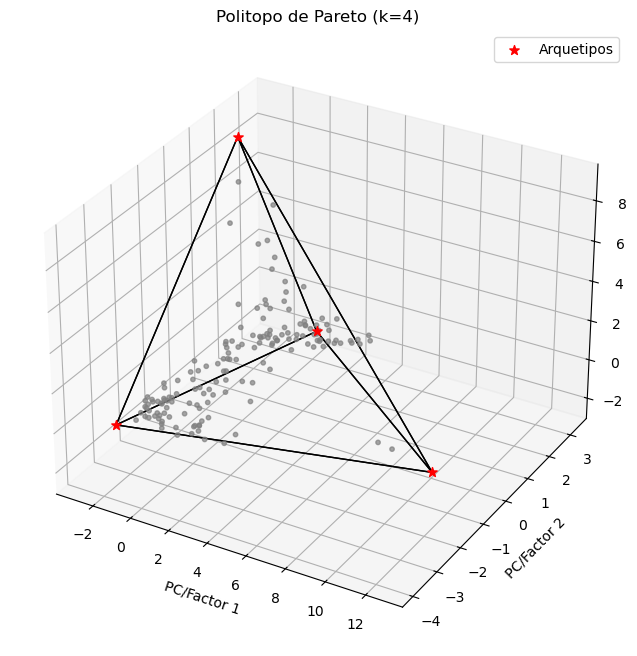


Quality of polytope:
- Explained variance:  0.9847482
- t-ratio: 0.8114958873462268


In [44]:
# Optimize Pareto TI for k=4 archetypes with relaxed fitting
BEST_K = 4
res_final = pu.fit_pcha_partipy(
    X,
    k=BEST_K,
    max_iter=1000,
    tol=1e-8,
    delta=0.25,
)

# Extract results
archetypes = res_final["archetypes"]
S_matrix = res_final["S_matrix"]

# Visualization of polytope
p.plot_polytope_3d(X, archetypes, labels=None, title=f"Politopo de Pareto (k={BEST_K})")
print()

# Metrics for the fitting of the polytope
print("Quality of polytope:")
print("- Explained variance: ", res_final["explained_variance"])
print("- t-ratio:", res_final["t_ratio"])

Next, it is possible to examine the tasks associated with each archetype by observing which aspects of the metadata are enriched when approaching a particular archetype.

In the example below, we show oxygen as the metadata to be analyzed.

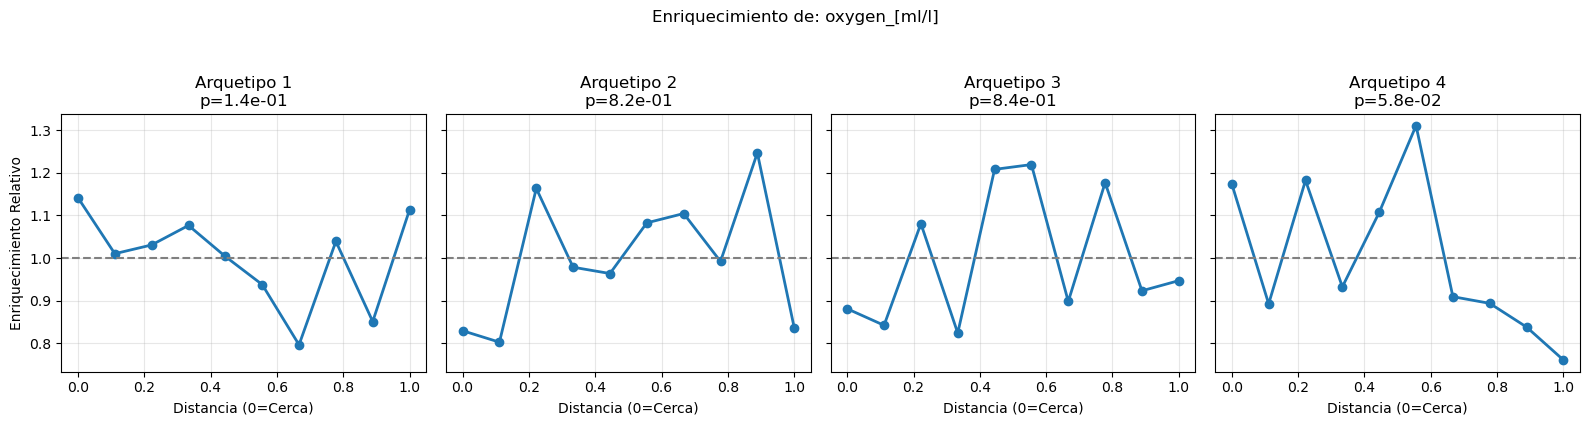

,archetype,p_value,max_enrichment
0,1,0.135201,1.140885
1,2,0.821680,0.830050
2,3,0.836220,0.882274
3,4,0.057688,1.175693


In [45]:
# We used 'metadata' DataFrame, previously loaded
feature = 'oxygen_[ml/l]'
assert feature in metadata.columns

# Method for enrichment
enrich_ox = pu.calculate_enrichment(X, archetypes, metadata, feature)
# Plot for enrichment
p.plot_enrichment_curves(enrich_ox)
# Summary with maximum enrichment for oxigen, and p-value for certanty
display(enrich_ox[["archetype", "p_value", "max_enrichment"]])

## Prediction models: how they work and why use them

Another implemented tool involves training predictive models on the samples to identify the features that "best explain" the metadata. Currently, it is possible to use Random Forest Regressor (RFR) and Random Forest Classifier (RFC) models.

Each method tries to find logical rules, using random trees (graphs), and selects the ones that best predict the trend of the data. Which method is used depends on the type of variable that one wants to predict: RFR is used to adjust to numerical data, and RFC is used to adjust to categorical data. 

The main objective for these exercises is to study correlation between features and environmental variables. In other words, the prediction models can be a tool to explore how features "predict" the environmental values as a indication of the influence of these environmental variables on the data. 

The following example demonstrates how to automatically train these models for four metadata features: depth (regression), temperature (regression), oxygen concentration (regression), and oxygen level (classification). We consider, in this example, the best prediction as the one with the greatest $R^2$ metric for regression, and $accuracy$ for classification.

After each prediction model is fitted, we show what dimension (in the example, factors for MOFA), best correlates with the studied environmental variable. 

=== Analysing: depth_m ===
-> Tuning Regressor for depth_m...
Best Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}
R2 (Test): 0.794 | RMSE: 77.886


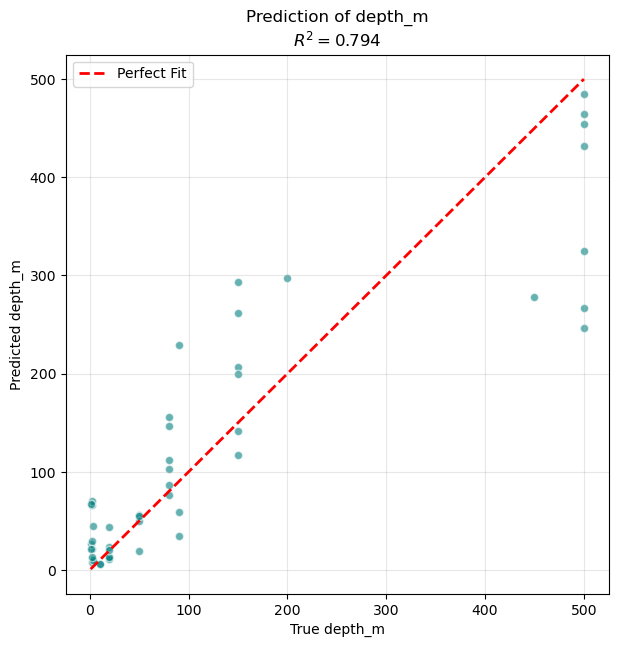

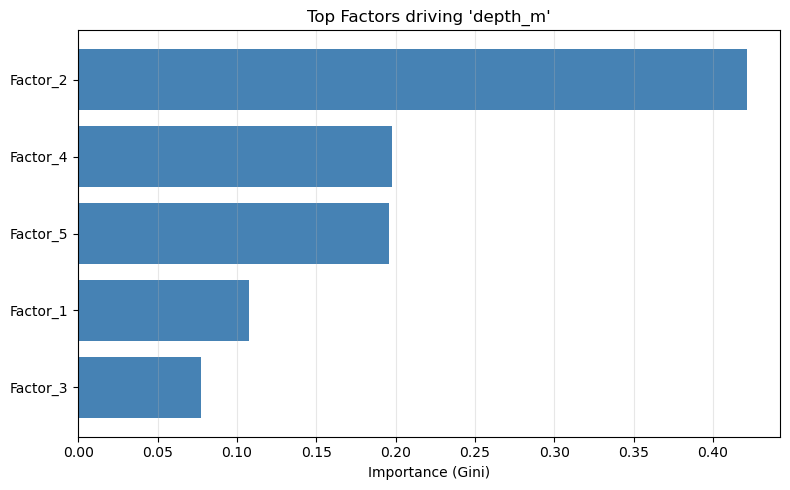


------------------------------------------------------------

=== Analysing: temperature_[c] ===
-> Tuning Regressor for temperature_[c]...
Best Parameters: {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 100}
R2 (Test): 0.797 | RMSE: 1.360


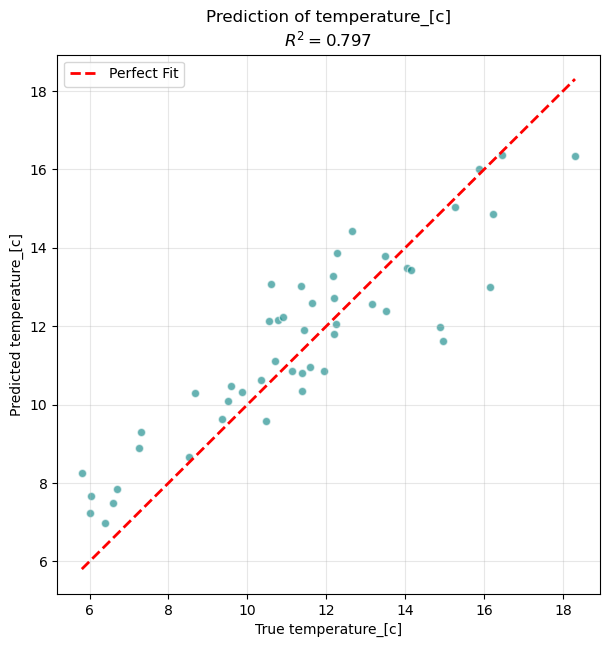

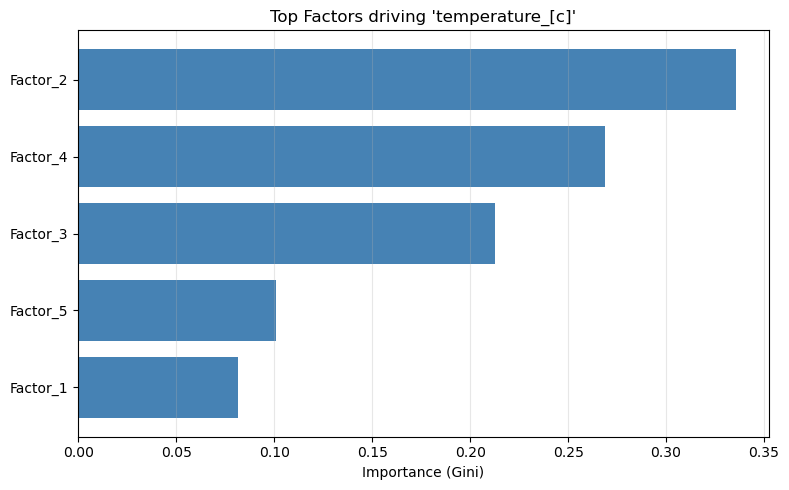


------------------------------------------------------------

=== Analysing: oxygen_[ml/l] ===
-> Tuning Regressor for oxygen_[ml/l]...
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
R2 (Test): 0.739 | RMSE: 1.049


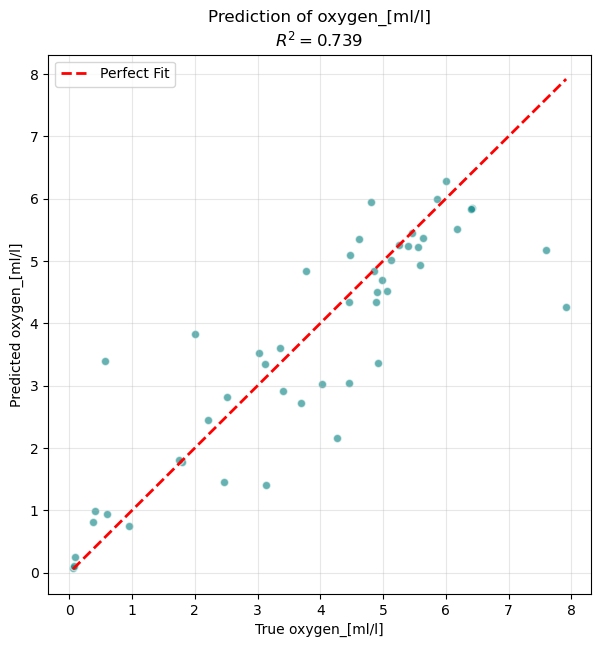

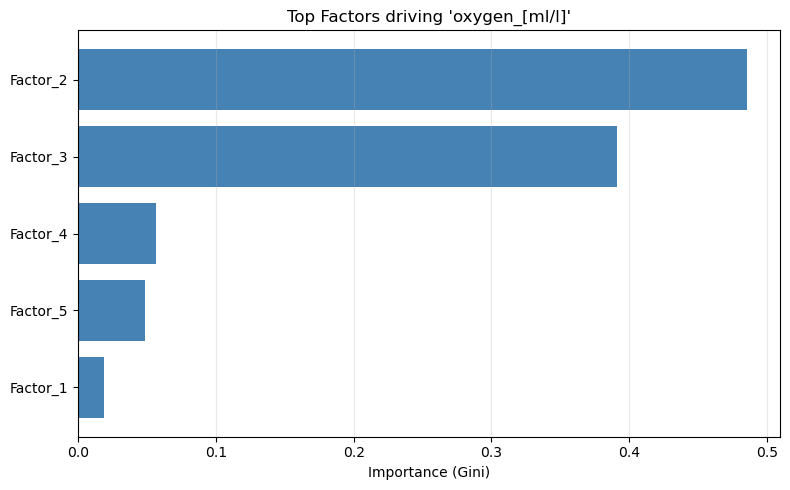


------------------------------------------------------------

=== Analysing: oxygen_level ===
-> Tuning Classifier for oxygen_level...
Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
Accuracy (Test): 0.872


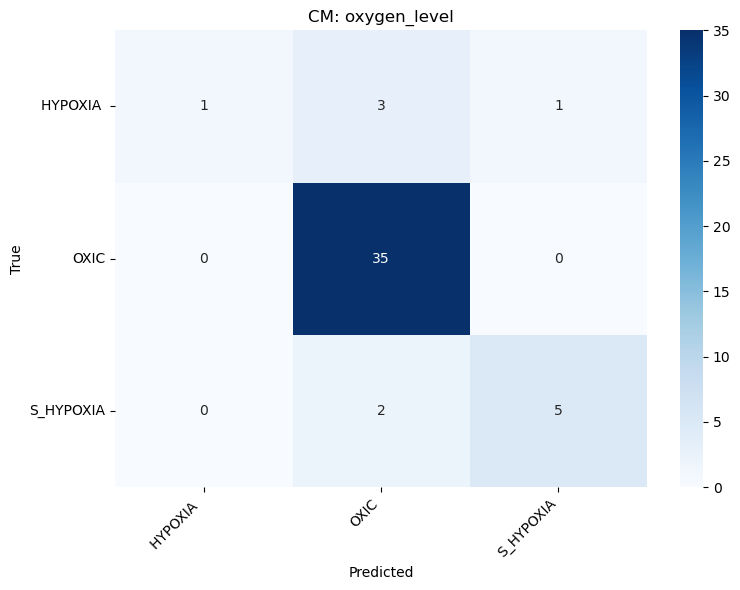

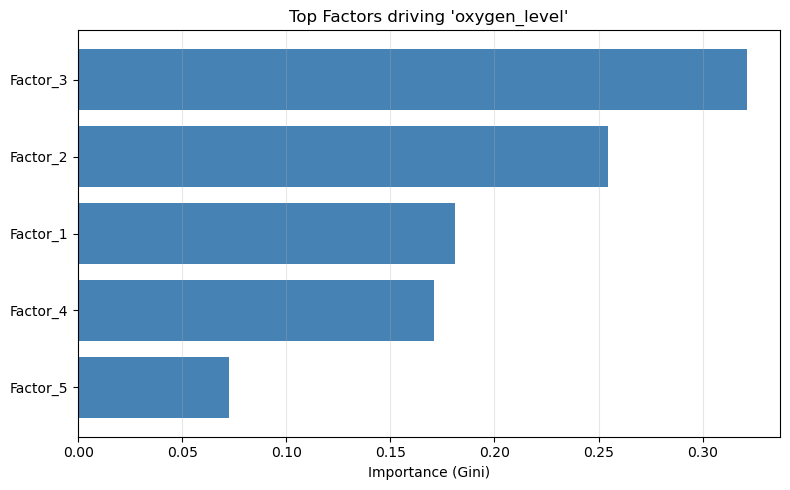


------------------------------------------------------------



In [46]:
# Slection of environmental variables
target_columns = [
    "depth_m",
    "temperature_[c]",
    "oxygen_[ml/l]",
    "oxygen_level",
]

# Selection of hyperparameter of each method. Tweak as you see fit
reg_params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_leaf": [1, 2, 4],
}

clf_params = {
    "n_estimators": [100, 200],
    "max_depth": [10, None],
    "criterion": ["gini", "entropy"],
    "min_samples_split": [2, 5],
}


valid_targets = [c for c in target_columns if c in metadata.columns] #Sanity check

# Automatization of the process
for target in valid_targets:
    print(f"=== Analysing: {target} ===")
    y = metadata[target]
    
    is_numeric = pd.api.types.is_numeric_dtype(y)
    num_unique = y.nunique()

# Based on the 'is_numeric' variable, use RFR or RFC accordingly
    
    if is_numeric and num_unique > 10:
        # Tunning for best hyperparameters
        res = pred.tune_metadata_regressor(df_mofa_pruned, y, param_grid=reg_params)
        
        if "error" in res:
            print(f"Skipping: {res['error']}")
            continue
            
        # Report best hyperparameters    
        print(f"Best Parameters: {res['best_params']}")
        print(f"R2 (Test): {res['r2']:.3f} | RMSE: {res['rmse']:.3f}")
        
        # Plot the best prediction
        p.plot_regression_results(res["y_test"], res["y_pred"], target, res["r2"])
        
    else:
        # Tunning for best hyperparameters
        res = pred.tune_metadata_classifier(df_mofa_pruned, y, param_grid=clf_params)
        
        if "error" in res:
            print(f"Skipping: {res['error']}")
            continue
        
        # Report best hyperparameters      
        print(f"Best Parameters: {res['best_params']}")
        print(f"Accuracy (Test): {res['accuracy']:.3f}")

        # Plot the best prediction
        p.plot_confusion_matrix(res["confusion_matrix"], res["classes"], f"CM: {target}")

    # Dimensions (factor) that best predict the environmental variable, visualized as a plot 
    imp = pred.get_factor_importance(res["model"], res["feature_names"])
    p.plot_factor_importance_bar(imp, target, top_n=5)
    
    print("\n" + "-"*60 + "\n")

In the previous plots, we can observe which factor best predict a particular variable. To retrieve the original features, we can use the weights associated to each view and see what are the relevant features that make up that factor.

Since the factor matrix ($Z$) is multiplied with a weight matrix ($W_M$) to obtain the views ($Y_m$), we first need to choose a view (in this case, taxonomic data or genomic data) to obtain what features are more relevant for each factor. We first show how to obtain the weight of each of the views.

In [47]:
##################################################################
#    Similar as the case when we first calculate MOFA, we use the
#    MUON library to handle the model. Then, instead of running
#    the optimization for MOFA, we simply open the .hdf5 file, and
#    use it to extract the weights for each view. Since we did not
#    do this previously, we show how to do it without using the
#    MOFA_analysis function from this toolbox.
##################################################################

#First, load the data 
NAMES_DATA = {
    'TEST/processed_data/clr_gene_M1.csv' : 'genes_M1', 
    'TEST/processed_data/clr_taxa_order.csv' : 'taxa_order' , 
}
mdata = create_mudata(NAMES_DATA)

# Then, open the model
mofa_model = mofa.mofa_model("TEST/processed_data/MOFA/mofa_model.hdf5")

# We obtain the weight matrices and save them in memory in a dictionary
W_model = get_weights_MOFA(MuData=mdata, model=mofa_model)

# We then can use W_model and/or save the matrices as CSV files
# Each matrix key is the same as the name of the data given in NAMES_DATA
for view_name, W in W_model.items():
    W_df = pd.DataFrame(
        W, 
        #To obtain the indices, we use the mdata object
        index = mdata.mod[view_name].var_names,
        columns = [f"Factor_{n}" for n in range(1,mofa_model.nfactors+1)] 
    )
    du.save_data(W_df, f"TEST/processed_data/MOFA/W_mofa_{view_name}")


C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\mudata\_core\mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
C:\ProgramData\anaconda3\envs\Omic_Integration\Lib\site-packages\mudata\_core\mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


With the weights obtained, one can start using them to study the feature importance for each factor (in each view).

For feature importance study in MOFA via plots, we recomend you see the following link: https://github.com/bioFAM/mofax/blob/master/notebooks/getting_started_pbmc10k.ipynb 


# 
If you have any questions about the tutorial, feel free to write at mcabezas@dim.uchile.cl 
